# Did any prompt, ban or knob make the models write a *new* algorithm? The novelty audit of `eval.py` (demo)

This notebook demonstrates the evaluation artifact **"Record repair and novelty audit of algorithm bans"** (iteration 3, Step 0). The study asks how prompt-level algorithm bans ("do not use BFS for this task") move a code model's choice of algorithm. The main model is **Qwen3-8B**; **Llama-3.1-8B-Instruct** is the second family. Every generated program was labelled with the algorithm it implements, out of a fixed catalogue per task:

* T1, grid path: BFS, DFS, bidirectional BFS, IDDFS, A\*, greedy best-first, IDA\*;
* T2, weighted shortest path: Dijkstra, Bellman-Ford/SPFA, bidirectional Dijkstra, Floyd-Warshall, Dial;
* a 13-task coding bench (k-th smallest, substring search, two-sum, cycle detection, merge intervals, top-k frequent and others), each task with a catalogue of its own.

A program outside its task's catalogue is labelled `other`. The 11 earlier experiments pushed the models in many ways:

* baselines;
* single, multiple and two-step bans;
* temperature, top-k and top-p;
* context seeds;
* instructions such as "make a fully novel algorithm";
* activation steering.

**The question here is whether any of those out-of-catalogue programs is a genuinely new algorithm.**

`eval.py` is the artifact's entry point and dispatches ten sections. This demo runs the two sections of the novelty audit (0c), using the artifact's own code split into cells.

1. **`judges`** (`sections/s0c_novelty.py`):
   * rebuilds the audit sets from the per-program records;
   * hash-commits the selection before any judge is consulted;
   * collects the verdicts of two blind LLM judges from different model families, with a third judge as tie-break;
   * includes 10 positive and 5 negative controls.

   The answers come from the cache that ships with the artifact, so the notebook makes **no paid API call**.
2. **`novelty`** (`sections/s0c_final.py`):
   * final classes, where a manual pass overrides a judge call only with a recorded reason;
   * Cohen's kappa between the two judges, with a bootstrap interval;
   * the control gate;
   * the novelty answer with its rule-of-three bound;
   * the multi-ban avoidance, recomputed with `other` kept separate.

**Data.** `mini_demo_data.json` holds 100 of the 228 programs audited in the full run:

* all 78 of **Set A**: every unique *correct* out-of-catalogue program;
* all 12 of **Set B_TOP**: exp9 `multi:TOP` programs outside the banned set;
* 10 of the 138 programs in **Set B**: failing out-of-catalogue programs from ban conditions.

It also carries everything else these two sections read:

* task specs and catalogue reference programs;
* the cached judge answers and the manual-pass records;
* label-only records of the four exp9 multi-ban conditions.

The other eight sections need data the demo does not carry: likelihood scores for `c1`, 0.95 GB of activation states for `manifold`, and all ~31,000 program records for `inventory`, `llama` and `knob`.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (same pin as the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, matplotlib, openai — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'openai==2.17.0')

In [2]:
from __future__ import annotations

# the import blocks of eval.py, common/paths.py, common/rows.py, common/stats.py, sections/s0c_novelty.py and
# sections/s0c_final.py, merged (the project's own modules are defined in the cells below instead of imported)
import argparse
import ast
import asyncio
import builtins
import hashlib
import json
import math
import os
import random
import re
import resource
import sys
import time
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any, Iterable, Iterator, Sequence

import numpy as np
import pandas as pd
from loguru import logger
from scipy.stats import norm

# notebook additions: demo workspace, module stand-ins, figures
import shutil
import types

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-3/evaluation-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
META = data["metadata"]
EXAMPLES = data["datasets"][0]["examples"]   # one audited program (one origin-file record) per example
print(f"{len(EXAMPLES)} programs {dict(Counter(e['set'] for e in EXAMPLES))}, {sum(e['pinned'] for e in EXAMPLES)} of "
      f"them exp9 multi-ban programs; {len(META['side_rows'])} label-only multi-ban records; "
      f"{len(META['files'])} dependency files; {len(META['judge_cache'])} cached judge responses; "
      f"{len(META['manual_pass'])} manual-pass records")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
100 programs {'A': 78, 'B_TOP': 12, 'B': 10}, 15 of them exp9 multi-ban programs; 385 label-only multi-ban records; 116 dependency files; 264 cached judge responses; 98 manual-pass records


## Configuration

Every tunable parameter is in the next cell, with the full run's value in the comment.

* **`MAX_PROGRAMS`** is how many of the 100 demo programs go into the audit, taken in order: Set A first, then B_TOP, then B. The 15 exp9 multi-ban programs are always kept, because the avoidance tally needs every record of those four conditions.
* **`N_KAPPA_BOOT`** is the number of bootstrap resamples behind the 95% interval of Cohen's kappa. The original hard-codes 2,000.
* **`SET_B_MAX`** is the Set B budget in `build_selection()`.
* **`CALL_JUDGES = True`** switches on the paid path of `run_judges()`. It needs `OPENROUTER_API_KEY` and `OPENROUTER_BASE_URL`, and it calls only for answers missing from the cache. With the shipped cache, no call is needed.
* The arguments of the eight sections that are not run here (`--n-boot`, `--n-sim`, …) are kept, so that `main()` below parses the same arguments as `eval.py`.

In [5]:
# ---- tunable parameters (full-run values in the comments) ----
MAX_PROGRAMS = 100        # demo programs fed to the audit, in order; the 15 pinned exp9 multi-ban programs are always
                          # added (demo data: 100 programs; full run: all 31,269 records -> 228 audited programs)
N_KAPPA_BOOT = 2000       # bootstrap resamples for the 95% interval of Cohen's kappa (full run: 2000)
SET_B_MAX = 150           # Set B budget of build_selection() (full run: 150)
CALL_JUDGES = False       # False: judge answers from the cache (free); True: call OpenRouter for any missing answer
                          # (paid; needs OPENROUTER_API_KEY and OPENROUTER_BASE_URL; eval.py always takes this path)
REUSE_JUDGE_CACHE = True  # eval.py --reuse-judge-cache (default True; --fresh-judges sets it to False and spends money)
SECTIONS_TO_RUN = ["judges", "novelty"]   # the eval.py sections the demo data supports (full run: all ten)
# arguments of the sections not run here (c1, manifold), kept so main() parses what eval.py parses (full-run defaults)
N_BOOT, N_SIM, N_PERM, N_NULL, N_POWER, WORKERS = 2000, 10000, 500, 200, 200, 6

## Demo workspace: the loaded data in the layout the original code reads

The original code reads files, not variables. It reads two kinds:

* the dependencies' origin files and task folders, through `common/paths.py: dep_root()`, which resolves each dependency to `$AII_DEPS_ROOT/<artifact_id>` first (the hook the artifact provides for forks);
* its own `audit/` folder.

So instead of editing every reader, the next cell writes the loaded data into a small folder with exactly that layout and sets `AII_DEPS_ROOT`. The layout has three parts:

* `deps/<artifact_id>/…`
  * the task specs and catalogue reference programs of exp1 and exp9;
  * the bench specs and references of exp11;
  * one JSONL origin file per experiment, holding the demo's records in their original order.
* `audit/judge_cache.jsonl`, the judges' cached answers. The raw response text is left out; the parsed JSON object is kept.
* `audit/manual_pass.jsonl`, the executor's manual reading of the programs.

From here on, every function runs unchanged on the demo files. Line numbers in the provenance of the outputs refer to these smaller files.

In [6]:
DEMO_WS = Path("eval_demo_ws").resolve()      # stands in for the artifact's folder (eval.py's WS)
shutil.rmtree(DEMO_WS, ignore_errors=True)    # start from an empty workspace on every run
DEPS_DIR = DEMO_WS / "deps"
os.environ["AII_DEPS_ROOT"] = str(DEPS_DIR)   # common/paths.py: dep_root() looks here first

# 1. dependency files, verbatim: task specs, catalogue reference programs, bench specs ("<artifact_id>/<path>")
for rel, text in META["files"].items():
    (DEPS_DIR / rel).parent.mkdir(parents=True, exist_ok=True)
    (DEPS_DIR / rel).write_text(text)

# 2. origin files: the demo programs (the first MAX_PROGRAMS, plus every pinned one) and the label-only multi-ban
#    records, one JSONL file per origin file, in their original order
use = [e for i, e in enumerate(EXAMPLES) if i < MAX_PROGRAMS or e["pinned"]]
by_file = defaultdict(list)
for e in use + META["side_rows"]:
    by_file[(e["aid"], e["rel"])].append(e)
for (aid, rel), es in sorted(by_file.items()):
    (DEPS_DIR / aid / rel).parent.mkdir(parents=True, exist_ok=True)
    with (DEPS_DIR / aid / rel).open("w") as fh:
        for e in sorted(es, key=lambda x: x["line"]):
            fh.write(json.dumps(e["record"]) + "\n")

# 3. the artifact's own audit files: the cached judge answers and the manual pass
(DEMO_WS / "audit").mkdir(parents=True)
for name, recs in (("judge_cache.jsonl", META["judge_cache"]), ("manual_pass.jsonl", META["manual_pass"])):
    with (DEMO_WS / "audit" / name).open("w") as fh:
        for r in recs:
            fh.write(json.dumps(r) + "\n")
(DEMO_WS / "tables").mkdir()   # the artifact ships tables/; pandas' to_csv() does not create folders

print(f"{len(use)} demo programs {dict(Counter(e['set'] for e in use))} + {len(META['side_rows'])} label-only records "
      f"in {len(by_file)} origin files:")
for (aid, rel), es in sorted(by_file.items()):
    print(f"  {aid}:{rel}: {len(es)} records")

100 demo programs {'A': 78, 'B_TOP': 12, 'B': 10} + 385 label-only records in 8 origin files:
  art_-QPYRaFERCBX:data/labelled.jsonl: 8 records
  art_0ndRfWKBWclR:data/samples_forced.jsonl: 14 records
  art_8_ULPE8jJQc_:data/samples.jsonl: 1 records
  art_D6Z0Snf09sFL:data/samples_phaseC.jsonl: 1 records
  art_HF8nK8B_Lqyy:runs/samples.jsonl: 4 records
  art_IVZc3TWCeE9f:data/samples.jsonl: 447 records
  art_U5UKkFrOgSsE:data/samples.jsonl: 7 records
  art__skdlFp_o3e9:data/samples.jsonl: 3 records


## The shared modules (`common/`)

### `common/paths.py`: where everything lives

* **Dependencies.** The eleven dependencies are addressed by artifact id (`DEPS`, `EXP`). Every number in the outputs cites its source as `<artifact_id>:<relative path>` (`src()`).
* **De-duplication.** `code_key()` gives a program its key: the sha256 of the code with trailing whitespace stripped. The audit counts *unique* programs by this key.
* **Changes in the notebook.** Two lines differ from the original:
  * `WS`, the artifact folder, is the demo workspace;
  * the run-volume fallback `RUNS` no longer indexes five parent folders up. That fallback is never reached here, because `AII_DEPS_ROOT` is set.

In [7]:
# common/paths.py
# """Workspace and dependency locations, resolved relative to this repository (no absolute server paths).
#
# Every dependency is read in place, read-only. A dependency is addressed as `<artifact_id>:<relative path>` in all
# outputs; `src(aid, rel)` builds that citation string and `dep(aid, rel)` the readable Path.
# """

WS = DEMO_WS   # notebook: the demo workspace written above (original: Path(__file__).resolve().parent.parent)
# runs root = <runs>/<run>/3_invention_loop/iter_3/gen_art/<this workspace>; overridable for a fork
# notebook: default str(WS.parent) instead of str(WS.parents[4]), which needs a five-level-deep folder; it is never used
# here because AII_DEPS_ROOT is set
RUNS = Path(os.environ.get("AII_RUNS_ROOT", str(WS.parent)))

DEPS: dict[str, str] = {
    "art__skdlFp_o3e9": "run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_experiment_1",   # exp1
    "art_D6Z0Snf09sFL": "run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_experiment_2",   # exp2
    "art_U5UKkFrOgSsE": "run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_experiment_4",   # exp4
    "art_HF8nK8B_Lqyy": "run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_experiment_5",   # exp5
    "art_UoCVh2Qe5RZ0": "run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_experiment_6",   # exp6
    "art_6zBfl3kDjeiP": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_7",   # exp7
    "art_8_ULPE8jJQc_": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_8",   # exp8
    "art_IVZc3TWCeE9f": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_9",   # exp9
    "art_-QPYRaFERCBX": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_10",  # exp10
    "art_0ndRfWKBWclR": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_11",  # exp11
    "art_3iv5G76C3yoX": "run_aRfWvcSWjssb/3_invention_loop/iter_2/gen_art/gen_art_experiment_12",  # exp12
}
EXP = {"exp1": "art__skdlFp_o3e9", "exp2": "art_D6Z0Snf09sFL", "exp4": "art_U5UKkFrOgSsE", "exp5": "art_HF8nK8B_Lqyy",
       "exp6": "art_UoCVh2Qe5RZ0", "exp7": "art_6zBfl3kDjeiP", "exp8": "art_8_ULPE8jJQc_", "exp9": "art_IVZc3TWCeE9f",
       "exp10": "art_-QPYRaFERCBX", "exp11": "art_0ndRfWKBWclR", "exp12": "art_3iv5G76C3yoX",
       "exp3": "art_8_ULPE8jJQc_"}   # exp3 programs are read only through the pools copy shipped inside exp8
REPORT_REL = "run_aRfWvcSWjssb/3_invention_loop/iter_3/gen_strat/current_report.md"  # iteration-2 report (old wording)

RESULTS = WS / "results"
TABLES = WS / "tables"
FIGS = WS / "figures"
AUDIT = WS / "audit"
LOGS = WS / "logs"
SEED = 20261020


DEPS_ROOT_ENV = "AII_DEPS_ROOT"  # optional: a directory holding one folder per dependency, named by its artifact id


def dep_root(aid: str) -> Path:
    """Folder of dependency `aid`, looked up in this order:
    1. $AII_DEPS_ROOT/<artifact_id>;
    2. ../<artifact_id> (the published repository: every artifact is a sibling folder named by its id);
    3. the AI Inventor run-volume layout, relative to this repository (RUNS / DEPS[aid])."""
    env = os.environ.get(DEPS_ROOT_ENV)
    if env:
        return Path(env) / aid
    sib = WS.parent / aid
    if sib.is_dir():
        return sib
    return RUNS / DEPS[aid]


def dep(aid_or_exp: str, rel: str = "") -> Path:
    aid = EXP.get(aid_or_exp, aid_or_exp)
    return dep_root(aid) / rel


def src(aid_or_exp: str, rel: str) -> str:
    aid = EXP.get(aid_or_exp, aid_or_exp)
    return f"{aid}:{rel}"


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    out = []
    with Path(p).open() as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    continue
    return out


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def _default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        v = float(o)
        return None if not math.isfinite(v) else v
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (set, tuple)):
        return list(o)
    if isinstance(o, Path):
        return str(o)
    return str(o)


def clean(o: Any) -> Any:
    """Recursively replace non-finite floats by None so the JSON is standard."""
    import numpy as np

    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (float, np.floating)):
        v = float(o)
        return v if math.isfinite(v) else None
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.ndarray):
        return clean(o.tolist())
    if isinstance(o, np.bool_):
        return bool(o)
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(clean(obj), indent=indent, default=_default))
    tmp.replace(p)


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("w") as fh:
        for r in rows:
            fh.write(json.dumps(clean(r), default=_default) + "\n")


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def code_key(code: str) -> str:
    """De-duplication key: sha256 of the code with trailing whitespace stripped from every line and the ends."""
    norm = "\n".join(line.rstrip() for line in (code or "").strip().splitlines())
    return sha256_text(norm)

### `common/stats.py`: Wilson interval and Cohen's kappa

The two sections run here use two helpers of the artifact's statistics toolkit:

* the **Wilson score interval** for a proportion, used for the avoidance shares;
* **Cohen's kappa**, the agreement between two raters corrected for chance: $\kappa = (p_o - p_e)/(1 - p_e)$, where $p_o$ is the observed agreement and $p_e$ the agreement expected from the raters' marginal class frequencies.

The rest of the module serves the `c1`, `llama` and `knob` sections, which are not run here: the Newcombe interval, the Hill numbers (plug-in, Miller-Madow, rarefied), the Kish ESS and the PSIS k-hat.

In [8]:
# common/stats.py (the two functions the novelty sections use)
# """Small statistics toolkit: Wilson / Newcombe intervals, Hill numbers (plug-in, Miller-Madow, rarefied),
# Cohen's kappa, Kish ESS and the PSIS generalized-Pareto k-hat (Zhang & Stephens 2009, as used by Vehtari et al.)."""


def wilson(k: int, n: int, conf: float = 0.95) -> tuple[float, float]:
    if n <= 0:
        return (math.nan, math.nan)
    z = norm.ppf(1 - (1 - conf) / 2)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def cohen_kappa(a: Sequence[str], b: Sequence[str]) -> float:
    a, b = list(a), list(b)
    n = len(a)
    if n == 0:
        return math.nan
    cats = sorted(set(a) | set(b))
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[c] * cb[c] for c in cats) / (n * n)
    return float((po - pe) / (1 - pe)) if pe < 1 else (1.0 if po == 1 else math.nan)

### `common/rows.py`, part 1: catalogues and label normalisation

Each of the eleven experiments wrote its own per-program records, with its own field names and label spellings (`bidir_bfs`, `bellman_ford_spfa`, `unit_dijkstra`, …). `norm_label()` folds every raw label into the analysis catalogues: six algorithms for T1, five for T2, and exp9's seven for T1. What falls outside becomes one of three labels:

* `other`, the labeller's own out-of-catalogue call;
* `other_ext`, a known name outside the analysis catalogue, such as JPS or Johnson;
* `unparseable`.

The first two make a correct program a **novelty candidate**. The parsing helpers recover each record's decoding settings (temperature, top-k, top-p, thinking) and its banned set.

In [9]:
# common/rows.py, part 1
# """Normalise every per-program record of the ORIGIN files (exactly the files named in the plan's builds_on) to one row
# schema:
#
#   {exp, task, model, condition, kind, banned_set, template, T, top_k, top_p, thinking, label, label_fine, passed,
#    code, code_sha256, source, line, arm, decoding_key, dedup_key}
#
# Copies of exp1/exp2/exp4 that exp7, exp8 and exp12 carry under inputs/, data_in/ or canon/ are never read (the exp3
# pools copy inside exp8 is the single exception: it is the only legitimate route to exp3 programs).
# """
# from common.paths import code_key, dep, read_jsonl, src   (notebook: defined above)

MODAL = {"t1": "bfs", "t2": "dijkstra"}
T1_K6 = ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"]          # exp7 analysis catalogue (T1)
T2_K5 = ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]               # exp7 analysis catalogue (T2)
E9_T1_K7 = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "idastar"]      # exp9 analysis catalogue (T1)

# raw name -> (canonical K=6/K=5 label, fine label)
_T1 = {"bfs": "bfs", "dfs": "dfs", "bibfs": "bibfs", "bidir_bfs": "bibfs", "bidirectional_bfs": "bibfs",
       "iddfs": "iddfs", "astar_gbfs": "astar_gbfs", "astar_greedy": "astar_gbfs", "astar": "astar_gbfs",
       "gbfs": "astar_gbfs", "dijkstra": "dijkstra", "dijkstra_unit": "dijkstra", "unit_dijkstra": "dijkstra",
       "idastar": "idastar", "jps": "other_ext", "biastar": "other_ext"}
_T2 = {"dijkstra": "dijkstra", "bf_spfa": "bf_spfa", "bellman_ford": "bf_spfa", "spfa": "bf_spfa",
       "bellman_ford_spfa": "bf_spfa", "bidijkstra": "bidijkstra", "bidir_dijkstra": "bidijkstra",
       "bidirectional_dijkstra": "bidijkstra", "floyd": "floyd", "floyd_warshall": "floyd", "dial": "dial",
       "johnson": "other_ext", "dag_dp": "other_ext"}
_OTHER = {"other", "unknown", "none"}
_UNPARSE = {"no_code", "unparseable", "invalid", "parse_error", "no code"}


def _s(v: Any) -> str | None:
    if v is None:
        return None
    s = str(v)
    return None if s in ("None", "", "nan") else s


def norm_task(t: Any) -> str:
    s = str(t)
    return s.lower() if s.upper() in ("T1", "T2") else s


def norm_model(m: Any) -> str:
    s = str(m or "")
    if "Base" in s:
        return "Qwen/Qwen3-8B-Base"
    if "llama" in s.lower():
        return "meta-llama/Llama-3.1-8B-Instruct"
    if "Qwen3-8B" in s:
        return "Qwen/Qwen3-8B"
    return s


def norm_label(task: str, raw: Any, code: str | None, parse_ok: bool | None = None, exp: str = "") -> tuple[str, str]:
    """Returns (label, label_fine). label is 'other' / 'other_ext' / 'unparseable' or a catalogue name."""
    r = _s(raw)
    has_code = bool(code and code.strip())
    if parse_ok is None:
        parse_ok = has_code
    if r is None:
        return ("other", "other:null_label") if parse_ok else ("unparseable", "unparseable")
    low = r.strip().lower()
    if low in _UNPARSE:
        return ("unparseable", low)
    if low in _OTHER or low.startswith("other"):
        return ("other", low)
    if task == "t1":
        if exp == "exp9" and low in ("dijkstra_unit", "unit_dijkstra", "jps", "biastar"):
            return ("other_ext", low)        # outside exp9's K=7 analysis catalogue
        if low in _T1:
            lab = _T1[low]
            return (lab, low if low in ("astar", "gbfs", "astar_greedy") else lab)
        return ("other_ext", low)
    if task == "t2":
        if low in _T2:
            return (_T2[low], _T2[low])
        return ("other_ext", low)
    return (low, low)                         # bench tasks keep their own mode names


def parse_decoding(dec: Any, row: dict[str, Any]) -> dict[str, Any]:
    s = str(dec or "")
    out = {"T": None, "top_k": None, "top_p": None, "thinking": None}
    m = re.search(r"(?:^|[^a-z])T(?:=|')?\s*:?\s*([0-9.]+)", s) or re.search(r"temperature'?\s*[:=]\s*([0-9.]+)", s)
    if m:
        out["T"] = float(m.group(1).rstrip("."))
    m = re.search(r"top_?p'?\s*[:=]?\s*([0-9.]+)", s) or re.search(r"topp([0-9.]+)", s)
    if m:
        try:
            out["top_p"] = float(m.group(1).rstrip("._"))
        except ValueError:
            pass
    m = re.search(r"top_?k'?\s*[:=]?\s*'?(-?[0-9]+|off|disabled)", s) or re.search(r"topk-?(off|[0-9]+)", s)
    if m:
        v = m.group(1)
        out["top_k"] = None if v in ("off", "disabled", "0", "-1") else int(v)
    if "thinkoff" in s or "thinking=off" in s or "'thinking': False" in s:
        out["thinking"] = False
    elif "thinkon" in s or "thinking=on" in s or "'thinking': True" in s:
        out["thinking"] = True
    if row.get("T") not in (None, "None"):
        try:
            out["T"] = float(row["T"])
        except (TypeError, ValueError):
            pass
    if row.get("temperature") not in (None, "None"):
        try:
            out["T"] = float(row["temperature"])
        except (TypeError, ValueError):
            pass
    if row.get("thinking") not in (None, "None"):
        out["thinking"] = str(row["thinking"]) in ("True", "true", "1")
    # defaults of every experiment in this study: thinking off, top-p 1.0, no top-k unless stated otherwise
    if out["thinking"] is None:
        out["thinking"] = False
    if out["top_p"] is None:
        out["top_p"] = 1.0
    return out


def _banned_from_str(s: Any) -> list[str]:
    if s is None:
        return []
    if isinstance(s, list):
        return [str(x) for x in s]
    t = str(s)
    if t in ("None", "", "[]"):
        return []
    try:
        v = ast.literal_eval(t)
        if isinstance(v, (list, tuple)):
            return [str(x) for x in v]
    except (ValueError, SyntaxError):
        pass
    return [t]


def _norm_banned(task: str, names: list[str], exp: str = "") -> list[str]:
    out = []
    for n in names:
        lab, fine = norm_label(task, n.lower(), "x", True, exp)
        out.append(fine if (exp == "exp9" and fine in ("astar", "gbfs")) else lab)
    return sorted(set(out))


def banned_for(exp: str, task: str, cond: str, r: dict[str, Any]) -> list[str]:
    c = cond or ""
    if exp == "exp1":
        return _norm_banned(task, _banned_from_str(r.get("banned_set")))
    if exp == "exp9":
        return _norm_banned(task, _banned_from_str(r.get("banned")), "exp9")
    if exp == "exp10":
        if c.startswith("ban:"):
            return _norm_banned(task, [c.split(":")[1]])
        if c.startswith("twostep:"):
            return _norm_banned(task, c.split(":")[1].split("+"))
        return []
    if exp in ("exp8",):
        return [MODAL[task]] if c in ("a", "c", "d", "K0", "K1", "K2") else []
    if exp in ("exp12", "exp3"):
        return [MODAL[task]] if c == "ban" else []
    if exp == "exp4" and c.startswith("succession"):
        return ["bfs", "dfs"] if task == "t1" else ["dijkstra", "bf_spfa"]
    if c.startswith("ban:"):
        return _norm_banned(task, c.split(":", 1)[1].split("+"))
    return []

### `common/rows.py`, part 2: the origin files and the row schema

`iter_rows()` reads exactly the origin files the plan named. There are 16 per-program files from the 11 artifacts; exp3 is reached only through the pools copy inside exp8, and seven extra exp12 label files are read for the novelty audit only. `normalise()` maps each record to one schema and adds three fields:

* `banned_set`;
* `decoding_key`;
* `dedup_key = task|sha256(code)`, which the audit uses to count each program once, however many files carry it.

In the full run this produces 31,269 rows. Here it reads the demo's 100 programs plus the 385 label-only multi-ban records.

In [10]:
# common/rows.py, part 2
# exactly the origin files named in builds_on: (exp, relative path, model-agnostic tag)
ORIGIN_FILES = [
    ("exp1", "data/samples.jsonl"),
    ("exp2", "data/samples_phaseA.jsonl"), ("exp2", "data/samples_phaseC.jsonl"), ("exp2", "data/samples_phaseD.jsonl"),
    ("exp4", "data/samples.jsonl"),
    ("exp5", "runs/samples.jsonl"),
    ("exp6", "results/samples.jsonl"),
    ("exp3", "inputs/iter1/exp3/generations/pools.jsonl"),
    ("exp7", "data/forced_selected.jsonl"),
    ("exp8", "data/samples.jsonl"),
    ("exp9", "data/samples.jsonl"),
    ("exp10", "data/labelled.jsonl"),
    ("exp11", "data/samples_pilot.jsonl"), ("exp11", "data/samples_llama_pilot.jsonl"),
    ("exp11", "data/samples_forced.jsonl"),
    ("exp12", "results/samples.jsonl"),
]
# extra exp12 per-readout label files: read for the novelty audit only (de-duplicated by code hash)
EXP12_EXTRA = [f"results/labelled_{k}.jsonl" for k in ("c1", "c2", "c3", "c4", "crn", "det", "rep10")]


def _passed(v: Any) -> bool | None:
    if v is None:
        return None
    s = str(v)
    if s in ("True", "true", "1"):
        return True
    if s in ("False", "false", "0"):
        return False
    return None


def iter_rows(include_exp12_extra: bool = False) -> Iterator[dict[str, Any]]:
    files = list(ORIGIN_FILES) + ([("exp12", f) for f in EXP12_EXTRA] if include_exp12_extra else [])
    for exp, rel in files:
        p = dep(exp, rel)
        if not p.exists():
            continue
        for i, r in enumerate(read_jsonl(p)):
            yield normalise(exp, rel, i, r)


def normalise(exp: str, rel: str, i: int, r: dict[str, Any]) -> dict[str, Any]:
    task = norm_task(r.get("task", r.get("task_id")))
    code = r.get("code") if isinstance(r.get("code"), str) else None
    if exp == "exp7":
        code = r.get("code_raw") or r.get("code") or r.get("code_scrubbed")
        cond = f"forced:{r.get('j')}"
        raw_label = r.get("label", r.get("j"))
    else:
        cond = str(r.get("condition"))
        raw_label = r.get("label")
    parse_ok = None
    if exp == "exp5" and r.get("parse_ok") is not None:
        parse_ok = str(r.get("parse_ok")) == "True"
    label, fine = norm_label(task, raw_label, code, parse_ok, exp)
    dec = parse_decoding(r.get("decoding"), r)
    if exp == "exp6" and r.get("key"):
        k = str(r["key"]).split("|")
        try:
            dec["T"] = float(k[5][1:])
            dec["top_k"] = 10 if k[6] == "topk10" else None
            dec["top_p"] = 0.95 if k[6] == "topp095" else 1.0
            dec["thinking"] = k[7] == "think1"
        except (IndexError, ValueError):
            pass
    if exp == "exp1" and cond == "baseline_T13":
        dec["T"] = 1.3
    arm = _s(r.get("arm")) or _s(r.get("steering")) or _s(r.get("steer"))
    model = norm_model(r.get("model"))
    if exp == "exp7":
        model = "Qwen/Qwen3-8B"
    tmpl = _s(r.get("template")) or _s(r.get("paraphrase_id"))
    banned = banned_for(exp, task, cond, r)
    dk = f"T{dec['T']}|k{dec['top_k']}|p{dec['top_p']}|think{dec['thinking']}"
    return {"exp": exp, "task": task, "model": model, "model_raw": str(r.get("model")), "condition": cond,
            "kind": _s(r.get("kind")), "banned_set": banned, "template": tmpl, **dec, "decoding_key": dk,
            "label": label, "label_fine": fine, "label_raw": _s(raw_label), "passed": _passed(r.get("passed")),
            "code": code, "code_sha256": _s(r.get("code_sha256")),
            "dedup_key": f"{task}|{code_key(code)}" if code and code.strip() else None,
            "source": src(exp, rel), "line": i + 1, "arm": arm, "phase": _s(r.get("phase")),
            "X": _s(r.get("X")), "sample_id": _s(r.get("sample_id")),
            "runtime_label": _s(r.get("runtime_label") or r.get("rt_label") or r.get("label_runtime")),
            "ast_label": _s(r.get("ast_label") or r.get("label_ast")),
            "judge_label": _s(r.get("judge_label") or r.get("label_judge")),
            "variant": _s(r.get("variant")), "algorithm": _s(r.get("algorithm") or r.get("forced_mode"))}

## `eval.py`: logging, the section list, one entry point per section

`eval.py` logs to stdout and to `logs/run.log`. It lists its ten sections and gives each one an entry point `sec_<name>(args)`; `main()` (further below) calls the requested ones in order.

* **Sections not run here.** Their entry points stay verbatim. Each imports its module from the artifact's `sections/` package, which is not part of the demo, so they are defined but not called.
* **The two sections run here.**
  * `sec_judges` and `sec_novelty` call the notebook stand-ins `s0c_novelty` and `s0c_final`, whose code is in the cells below.
  * `sec_judges` takes `call_judges` from the configuration cell. The original always passes `True`, so it always opens an OpenRouter client: it needs the API keys even when every answer is cached.

In [11]:
# eval.py
# """Iteration-3 Step 0 evaluation: repair the iteration-2 record from data on disk and audit novel code (CPU only).
#
# Sections (run all, or one with --section):
#   inventory   S0  inputs/inventory.json, tables/label_map.csv, de-duplicated row counts
#   c1          0a  C1 likelihood diagnostics (argmax vs landing, implied mass, bootstrap/replicate, AIM null, M arithmetic)
#   manifold    0b  exp9 figures, implemented counts, g16 geometry with nulls and planted-loop power
#   judges      0c  blind LLM judges for the novelty audit (paid; cached in audit/judge_cache.jsonl)
#   novelty     0c  final classes, kappa, controls, manual pass merge, corrected multi-ban avoidance
#   llama       0d  Llama correct-only compositions and Hill numbers
#   knob        0e  knob table under a declared class rule (rarefied Hill-1 at depth 25)
#   positioning 0f  dated positioning rows (reads results/positioning_raw.json from the web check)
#   corrections 0h  corrections.json (12 record items)
#   assemble        full/mini/preview eval_out.json (exp_eval_sol_out)
#
# Usage: uv run eval.py [--section NAME] [--reuse-judge-cache] [--n-boot 2000]
# """
# notebook: WS = Path(__file__).resolve().parent, sys.path.insert(0, str(WS)) and
# `from common.paths import LOGS, RESULTS, write_json` are replaced by the cells above

LOGS.mkdir(parents=True, exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(LOGS / "run.log"), rotation="30 MB", level="DEBUG")

SECTIONS = ["inventory", "c1", "manifold", "judges", "novelty", "llama", "knob", "positioning", "corrections",
            "assemble"]


def _rows(include_extra: bool = False):
    # from common.rows import iter_rows   (notebook: defined above)

    return list(iter_rows(include_exp12_extra=include_extra))


def sec_inventory(args) -> None:
    from sections import s0_inventory

    s0_inventory.run(_rows(include_extra=True))


def sec_c1(args) -> None:
    from sections import s0a_c1

    s0a_c1.run(n_boot=args.n_boot, n_sim=args.n_sim)


def sec_manifold(args) -> None:
    from sections import s0b_manifold

    s0b_manifold.run(n_perm=args.n_perm, n_null=args.n_null, n_power=args.n_power, workers=args.workers)


def sec_judges(args) -> None:
    # from sections import s0c_novelty   (notebook: its code is in the cells below; `s0c_novelty` is a stand-in)

    # notebook: call_judges=CALL_JUDGES from the configuration cell (original: call_judges=True)
    out = s0c_novelty.run(_rows(include_extra=True), reuse_cache=args.reuse_judge_cache, call_judges=CALL_JUDGES)
    write_json(RESULTS / "novelty_judge_run.json", {"spend": out["spend"], "commit_sha256": out["commit_sha256"],
                                                    "control_scores": out["control_scores"],
                                                    "counts_unique": out["selection"]["counts_unique"],
                                                    "counts_with_duplicates": out["selection"]["counts_with_duplicates"]})


def sec_novelty(args) -> None:
    # from sections import s0c_final   (notebook: its code is in the cells below; `s0c_final` is a stand-in)

    s0c_final.run(_rows(include_extra=True))


def sec_llama(args) -> None:
    from sections import s0d_llama

    s0d_llama.run()


def sec_knob(args) -> None:
    from sections import s0e_knob

    s0e_knob.run(_rows(include_extra=False))


def sec_positioning(args) -> None:
    from sections import s0f_positioning

    s0f_positioning.run()


def sec_corrections(args) -> None:
    from sections import s0h_corrections

    s0h_corrections.run()


def sec_assemble(args) -> None:
    from sections import assemble

    assemble.run()

## Section `judges`: `sections/s0c_novelty.py`

### Part 1: judges, classes and catalogues

Two blind judges from different model families classify every audited program:

* judge **A** is `openai/gpt-4.1-mini`;
* judge **B** is `google/gemini-2.5-flash`, with reasoning off;
* when A and B disagree, judge **C**, `deepseek/deepseek-chat`, breaks the tie.

No Qwen or Llama model judges its own family's code. A judge sees only three things:

* the task specification;
* an *extended* catalogue with one line of mechanism per known algorithm. It includes textbook neighbours outside the study's labels: JPS, bidirectional A\*, Lee wavefront, beam search, Johnson, 0-1 BFS, DAG dynamic programming, and others;
* the code.

It answers with one of four classes:

| class | meaning |
|---|---|
| `LABELLER_MISS` | the program *is* a catalogue algorithm, possibly renamed or disguised |
| `CATALOGUE_VARIANT` | a hybrid or variant of a catalogue or textbook algorithm, which the judge must name |
| `NOVEL_ALGORITHM` | the mechanism matches no catalogue or textbook algorithm the judge knows |
| `DEGENERATE_OR_HARDCODED` | brute-force enumeration, special-casing of inputs, or literal outputs |

`INSTRUCTION_CONDS` flags the conditions that explicitly asked for something new: `instr_*`, `creative`, `new_algo`, `fully_novel`, enumeration, steering, `decommit`, `nonce`, removal.

In [12]:
# sections/s0c_novelty.py, part 1
# """(0c) Out-of-catalogue (novelty) audit.
#
# Set A = every unique correct program labelled 'other'/'other_ext' (both models, every condition, de-duplicated by
# (task, sha256 of trailing-whitespace-stripped code)); Set B = <= 150 failing 'other' programs from ban conditions
# (stratified, >= 5 per stratum where available) plus every exp9 multi:TOP program labelled outside the banned set.
# Two blind judges from different families (A openai/gpt-4.1-mini, B google/gemini-2.5-flash), tie-break C
# (deepseek/deepseek-chat) on disagreement; no Qwen or Llama judge. The judge sees spec + extended catalogue + code only.
# Positive controls (10 renamed catalogue references) and negative controls (5 degenerate programs) gate trust.
# """
# from common.paths import AUDIT, RESULTS, SEED, TABLES, dep, read_json, read_jsonl, sha256_text, src, write_json, write_jsonl
# from common.stats import cohen_kappa, wilson   (notebook: defined above)

JUDGES = {"A": "openai/gpt-4.1-mini", "B": "google/gemini-2.5-flash", "C": "deepseek/deepseek-chat"}
PRICE = {"openai/gpt-4.1-mini": (0.40, 1.60), "google/gemini-2.5-flash": (0.30, 2.50),
         "deepseek/deepseek-chat": (0.2574, 1.0287)}       # USD per M tokens (in, out), verified 2026-10-20
COST_STOP_USD = 1.30
CLASSES = ["NOVEL_ALGORITHM", "CATALOGUE_VARIANT", "LABELLER_MISS", "DEGENERATE_OR_HARDCODED"]
CACHE = AUDIT / "judge_cache.jsonl"
# SET_B_MAX = 150   (notebook: set in the configuration cell)

# one-line mechanism definitions: exp9 common.py MODE_DEFINITIONS (verbatim) + textbook neighbours named in the plan
T1_CAT = {
    "BFS": "breadth-first search: explores cells in order of distance from start with a FIFO queue (deque.popleft, list.pop(0), queue.Queue) or level-by-level frontier lists; one search direction; no priority queue.",
    "DFS": "depth-first search: follows one branch as deep as possible with recursion or a LIFO stack, with a visited set; a single pass with no depth limit and no restarts (neighbour ordering by distance is still DFS).",
    "bidirectional BFS": "two breadth-first searches, one from start and one from goal, expanded alternately until the frontiers meet; the path is joined at the meeting cell; no heuristic, no heap.",
    "IDDFS": "iterative deepening DFS: repeated depth-limited depth-first searches with an increasing depth limit (0, 1, 2, ...) until the goal is found; no heuristic bound.",
    "A*": "a priority queue (heap) ordered by f = g + h, cost so far plus a heuristic such as the Manhattan distance to the goal; one search direction.",
    "greedy best-first search": "a priority queue ordered by the heuristic h alone (e.g. Manhattan distance to the goal), ignoring the cost so far; one search direction.",
    "IDA*": "repeated depth-first searches bounded by f = g + h, raising the bound to the smallest f that exceeded it, until the goal is found.",
    "JPS (jump point search)": "A*-style search that jumps along straight lines and adds cells to the open list only at jump points (turning points next to walls, or the goal).",
    "bidirectional A*": "two A* searches, forward from start and backward from goal, each with its own heuristic-ordered heap, stopping when the frontiers meet.",
    "unit-weight Dijkstra": "a priority queue (heap) ordered by distance from start only, with no heuristic toward the goal.",
    "textbook neighbours": "beam search; random walk; wall following (left/right-hand rule); Lee wavefront (BFS distance labelling then backtrace); bidirectional Dijkstra on the grid.",
}
T2_CAT = {
    "Dijkstra's algorithm": "a single priority queue (heap) of tentative distances from s, popping the smallest distance each time (lazy deletion or decrease-key variants), one search direction.",
    "Bellman-Ford / SPFA": "Bellman-Ford (repeated relaxation passes over all edges, up to n-1 rounds, possibly with early exit) or SPFA (a FIFO queue of nodes whose distance improved, often with an in-queue flag).",
    "bidirectional Dijkstra": "two Dijkstra searches, forward from s on the graph and backward from t on the reversed graph, with a meeting/stopping rule.",
    "Floyd-Warshall": "all-pairs shortest paths with a triple loop over k, i, j updating dist[i][j] = min(dist[i][j], dist[i][k] + dist[k][j]).",
    "Dial's algorithm": "Dijkstra with a bucket queue: an array or dict of buckets indexed by distance, scanned in increasing distance order instead of a binary heap.",
    "DAG dynamic programming": "topological order then one relaxation pass (only valid on acyclic graphs).",
    "textbook neighbours": "Johnson's algorithm; A* with a non-zero heuristic; 0-1 BFS / deque-based shortest path; BFS ignoring weights; exhaustive DFS enumeration of all simple paths; memoised DFS over (node) states.",
}
INSTRUCTION_CONDS = re.compile(r"(instr_|creative|new_algo|fully_novel|enumerat|steer:dc|decommit|novelty|nonce|removal:)",
                               re.I)

SYSTEM = ("You are an expert in algorithms and program analysis. You classify the algorithmic MECHANISM of a Python "
          "program written for a stated task. You are not told who wrote it or why. Answer with one JSON object only.")

### Part 2: which programs are audited

`build_selection()` keys every program by `task|sha256(code)`, so a program that several files carry is counted once, with all its copies as provenance. It then builds three sets:

* **A**: every unique **correct** program labelled `other` or `other_ext`. These are the novelty candidates.
* **B_TOP**: every exp9 `multi:TOP` program outside the banned set, whatever its pass status, unless it is already in A. Together with the one Set A program from that condition, they make up the TOP ban's 13% "avoidance".
* **B**: failing `other` programs from ban conditions, up to `SET_B_MAX − |B_TOP|` of them. They are stratified by (experiment, task, model, ban family), with at least 5 per stratum where available, and shuffled with the global seed.

On the demo records the same code selects exactly the demo programs. This holds because Set A and B_TOP are complete here, and because the budget covers all 10 Set B programs.

In [13]:
# sections/s0c_novelty.py, part 2
# ------------------------------------------------------------------------------------------------ selection
def _ban_family(r: dict[str, Any]) -> str | None:
    c = r["condition"]
    if r["exp"] == "exp9":
        if c.startswith("multi:"):
            return "multi"
        if c.startswith("los:"):
            return "leave_one_survivor"
        if c.startswith("single:"):
            return "single"
        return None
    if r["exp"] == "exp10" and c.startswith("twostep"):
        return "two_step"
    if c.startswith("succession") or ("+" in c and c.startswith("ban:")):
        return "two_step"
    if r["banned_set"]:
        return "single"
    return None


def build_selection(rows: list[dict[str, Any]], set_b_max: int = SET_B_MAX) -> dict[str, Any]:
    rng = random.Random(SEED)
    by_key: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for r in rows:
        if r["dedup_key"]:
            by_key[r["dedup_key"]].append(r)

    def item(key: str, set_name: str) -> dict[str, Any]:
        prov = by_key[key]
        r0 = prov[0]
        return {"item_id": f"{set_name}|{key[:3]}{sha256_text(key)[:14]}", "set": set_name, "dedup_key": key,
                "task": r0["task"], "code": r0["code"], "label": r0["label"], "label_fine": r0["label_fine"],
                "passed": r0["passed"], "models": sorted({p["model"] for p in prov}),
                "exps": sorted({p["exp"] for p in prov}), "conditions": sorted({p["condition"] for p in prov}),
                "provenance": [{"source": p["source"], "line": p["line"], "condition": p["condition"],
                                "label": p["label_fine"], "passed": p["passed"]} for p in prov],
                "n_copies": len(prov)}

    setA_keys = sorted({r["dedup_key"] for r in rows if r["dedup_key"] and r["label"] in ("other", "other_ext")
                        and r["passed"] is True})
    A = [item(k, "A") for k in setA_keys]
    # exp9 multi:TOP programs outside the banned set (any label, any pass status)
    top_keys = []
    for r in rows:
        if r["exp"] == "exp9" and r["condition"] == "multi:TOP" and r["dedup_key"]:
            lab9 = r["label_fine"] if r["label_fine"] in ("astar", "gbfs") else r["label"]
            if lab9 not in r["banned_set"] and r["label"] != "unparseable" and r["dedup_key"] not in setA_keys:
                top_keys.append(r["dedup_key"])
    top_keys = sorted(set(top_keys))
    TOP = [item(k, "B_TOP") for k in top_keys]
    # failing 'other' programs from ban conditions, stratified (exp, task, model, ban family)
    taken = set(setA_keys) | set(top_keys)
    strata: dict[tuple, list[str]] = defaultdict(list)
    for r in rows:
        if (r["dedup_key"] and r["label"] == "other" and r["passed"] is False and r["dedup_key"] not in taken):
            fam = _ban_family(r)
            if fam:
                strata[(r["exp"], r["task"], r["model"], fam)].append(r["dedup_key"])
    for k in strata:
        strata[k] = sorted(set(strata[k]))
    budget = max(0, set_b_max - len(TOP))
    tot = sum(len(v) for v in strata.values())
    alloc = {}
    for k, v in strata.items():
        alloc[k] = min(len(v), max(5, int(round(budget * len(v) / max(1, tot)))))
    while sum(alloc.values()) > budget:          # trim the largest allocation first, never below 5 (or availability)
        kmax = max(alloc, key=lambda k: (alloc[k], str(k)))
        if alloc[kmax] <= 5:
            break
        alloc[kmax] -= 1
    B = []
    for k in sorted(strata, key=str):
        keys = list(strata[k])
        rng.shuffle(keys)
        for key in keys[:alloc[k]]:
            if key not in taken:
                taken.add(key)
                it = item(key, "B")
                it["stratum"] = "|".join(map(str, k))
                B.append(it)
    return {"A": A, "B_TOP": TOP, "B": B,
            "strata": {"|".join(map(str, k)): {"available": len(v), "allocated": alloc[k]} for k, v in strata.items()},
            "counts_with_duplicates": {"A": sum(i["n_copies"] for i in A), "B_TOP": sum(i["n_copies"] for i in TOP),
                                       "B": sum(i["n_copies"] for i in B)},
            "counts_unique": {"A": len(A), "B_TOP": len(TOP), "B": len(B)}}

### Part 3: controls that gate trust in the judges

The judges are trusted only if they pass a control gate of 15 items, with known answers.

* **10 positive controls.** Each is a catalogue reference program from exp1 (BFS, DFS, bidirectional BFS, IDDFS, A\*, Dijkstra, Bellman-Ford, Floyd-Warshall, Dial, bidirectional Dijkstra), disguised by an AST transformer. The transformer renames every identifier to `v1, v2, …`, except builtins and standard-library names, and removes docstrings. The expected answer is `LABELLER_MISS` with the right algorithm named.
* **5 negative controls.** Each is a hand-written degenerate program: lookup tables of known answers, or brute-force permutation search. The expected answer is `DEGENERATE_OR_HARDCODED`.

The gate passes with at least 9/10 positives and at least 4/5 negatives.

In [14]:
# sections/s0c_novelty.py, part 3
# ------------------------------------------------------------------------------------------------ controls
class _Renamer(ast.NodeTransformer):
    KEEP = set(dir(builtins)) | {"solve", "self", "heapq", "deque", "collections", "math", "sys", "itertools",
                                 "functools", "defaultdict", "heappush", "heappop", "heapify", "inf", "lru_cache",
                                 "Counter", "queue", "Queue", "PriorityQueue", "bisect", "typing", "List", "Tuple",
                                 "Optional", "Dict", "Set", "float", "heapreplace", "OrderedDict", "array"}

    def __init__(self) -> None:
        self.map: dict[str, str] = {}

    def _n(self, name: str) -> str:
        if name in self.KEEP:
            return name
        if name not in self.map:
            self.map[name] = f"v{len(self.map) + 1}"
        return self.map[name]

    def visit_Name(self, node: ast.Name) -> ast.AST:
        node.id = self._n(node.id)
        return node

    def visit_arg(self, node: ast.arg) -> ast.AST:
        node.arg = self._n(node.arg)
        node.annotation = None
        return node

    def visit_FunctionDef(self, node: ast.FunctionDef) -> ast.AST:
        node.name = self._n(node.name)
        node.returns = None
        if node.body and isinstance(node.body[0], ast.Expr) and isinstance(getattr(node.body[0], "value", None),
                                                                           ast.Constant) \
                and isinstance(node.body[0].value.value, str):
            node.body = node.body[1:] or [ast.Pass()]
        self.generic_visit(node)
        return node


def rename_code(code: str) -> str:
    tree = ast.parse(code)
    if tree.body and isinstance(tree.body[0], ast.Expr) and isinstance(getattr(tree.body[0], "value", None),
                                                                       ast.Constant):
        tree.body = tree.body[1:]
    tree = _Renamer().visit(tree)
    ast.fix_missing_locations(tree)
    return ast.unparse(tree)


POS_CONTROLS = [("t1", "bfs_deque_parent.py", "bfs"), ("t1", "dfs_stack.py", "dfs"), ("t1", "bibfs_sets.py", "bibfs"),
                ("t1", "iddfs_iterative.py", "iddfs"), ("t1", "astar_fg.py", "astar"),
                ("t2", "dijkstra_lazy.py", "dijkstra"), ("t2", "bellman_ford.py", "bf_spfa"),
                ("t2", "floyd_inf.py", "floyd"), ("t2", "dial_list.py", "dial"),
                ("t2", "bidijkstra_alternate.py", "bidijkstra")]

NEG_CONTROLS = [
    ("t1", "def solve(grid, start, goal):\n    if start == goal:\n        return [start]\n    known = {((0, 0), (0, 2)): [(0, 0), (0, 1), (0, 2)], ((0, 0), (2, 0)): [(0, 0), (1, 0), (2, 0)]}\n    if (tuple(start), tuple(goal)) in known:\n        return known[(tuple(start), tuple(goal))]\n    if len(grid) == 1 and len(grid[0]) == 2:\n        return [start, goal]\n    return []\n"),
    ("t1", "import itertools\n\ndef solve(grid, start, goal):\n    free = [(r, c) for r in range(len(grid)) for c in range(len(grid[0])) if grid[r][c] == '.']\n    if start not in free or goal not in free:\n        return []\n    if start == goal:\n        return [start]\n    middle = [p for p in free if p != start and p != goal]\n    for k in range(len(middle) + 1):\n        for combo in itertools.permutations(middle, k):\n            path = [start, *combo, goal]\n            if all(abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1 for a, b in zip(path, path[1:])):\n                return list(path)\n    return []\n"),
    ("t2", "def solve(n, edges, s, t):\n    table = {(2, 0, 1): 5, (3, 0, 2): 7, (4, 0, 3): 9}\n    if s == t:\n        return 0\n    if (n, s, t) in table:\n        return table[(n, s, t)]\n    if not edges:\n        return -1\n    return min(w for (u, v, w) in edges if u == s and v == t) if any(u == s and v == t for u, v, _ in edges) else -1\n"),
    ("t2", "import itertools\n\ndef solve(n, edges, s, t):\n    if s == t:\n        return 0\n    w = {}\n    for u, v, c in edges:\n        if (u, v) not in w or c < w[(u, v)]:\n            w[(u, v)] = c\n    best = -1\n    others = [x for x in range(n) if x not in (s, t)]\n    for k in range(len(others) + 1):\n        for mid in itertools.permutations(others, k):\n            path = [s, *mid, t]\n            if all((a, b) in w for a, b in zip(path, path[1:])):\n                cost = sum(w[(a, b)] for a, b in zip(path, path[1:]))\n                if best < 0 or cost < best:\n                    best = cost\n    return best\n"),
    ("t2", "def solve(n, edges, s, t):\n    if s == t:\n        return 0\n    answers = {0: -1, 1: 4, 2: 10, 3: 17, 4: 3}\n    return answers.get((n * 7 + len(edges) * 3 + s + t) % 5, -1)\n"),
]


def build_controls() -> list[dict[str, Any]]:
    out = []
    for task, fname, lab in POS_CONTROLS:
        d = "t1_grid" if task == "t1" else "t2_wsp"
        code = (dep("exp1", f"tasks/{d}/references/{fname}")).read_text()
        out.append({"item_id": f"CTRL_POS|{task}|{lab}", "set": "control_pos", "task": task, "code": rename_code(code),
                    "expected_class": "LABELLER_MISS", "expected_match": lab,
                    "source": src("exp1", f"tasks/{d}/references/{fname}")})
    for i, (task, code) in enumerate(NEG_CONTROLS):
        out.append({"item_id": f"CTRL_NEG|{task}|{i}", "set": "control_neg", "task": task, "code": code,
                    "expected_class": "DEGENERATE_OR_HARDCODED", "expected_match": None, "source": "hand-written"})
    return out

### Part 4: the judge prompt

`build_prompt()` puts together the four parts of a prompt:

* the task specification (T1/T2 from exp1, bench tasks from exp11's `spec.json`);
* the catalogue lines;
* the class definitions;
* the program.

It asks for one JSON object with these keys: `class`, `catalogue_match`, `closest_known_algorithm`, a mechanism summary, a rationale and a confidence.

The cache is keyed by `(judge, item_id, sha256(prompt))`, so an answer is reused only if the prompt rebuilt here is byte-identical to the prompt the judge saw. Every cache hit below therefore also checks that the demo reconstructs the full run's prompts exactly.

In [15]:
# sections/s0c_novelty.py, part 4
# ------------------------------------------------------------------------------------------------ prompt
_BENCH_DIRS: dict[str, Any] = {}


def bench_spec(task: str) -> tuple[str, dict[str, str]]:
    if not _BENCH_DIRS:
        for d in dep("exp11", "bench").iterdir():
            if d.is_dir() and (d / "spec.json").exists():
                _BENCH_DIRS[d.name.split("_")[0]] = d
    s = read_json(_BENCH_DIRS[task] / "spec.json")
    cat = s["catalogue"]
    if isinstance(cat, str):
        cat = ast.literal_eval(cat)
    return s["spec_text"], {c["display_name"]: c["mechanism"] for c in cat}


def spec_and_catalogue(task: str) -> tuple[str, dict[str, str]]:
    if task == "t1":
        return dep("exp1", "tasks/t1_grid/spec.txt").read_text().strip(), T1_CAT
    if task == "t2":
        return dep("exp1", "tasks/t2_wsp/spec.txt").read_text().strip(), T2_CAT
    return bench_spec(task)


def build_prompt(task: str, code: str) -> str:
    spec, cat = spec_and_catalogue(task)
    cat_lines = "\n".join(f"- {k}: {v}" for k, v in cat.items())
    return (f"TASK SPECIFICATION\n{spec}\n\nKNOWN-ALGORITHM CATALOGUE (one line of mechanism per entry)\n{cat_lines}\n\n"
            "CLASSES\n"
            "LABELLER_MISS: the program IS one of the catalogue algorithms above, possibly renamed or disguised "
            "(different identifiers, a queue built from a list, a stack replaced by recursion, extra checks).\n"
            "CATALOGUE_VARIANT: a hybrid or variant of a catalogue algorithm or of another textbook algorithm; you must "
            "name it.\n"
            "NOVEL_ALGORITHM: the mechanism matches no catalogue algorithm and no textbook algorithm you know.\n"
            "DEGENERATE_OR_HARDCODED: brute-force enumeration of candidates, special-casing of particular inputs, or "
            "literal outputs instead of an algorithm.\n"
            "Classify the MECHANISM only. The program may or may not be correct; correctness does not matter.\n\n"
            f"PROGRAM\n```python\n{code.strip()}\n```\n\n"
            "Return one JSON object with exactly these keys: \"class\" (one of LABELLER_MISS, CATALOGUE_VARIANT, "
            "NOVEL_ALGORITHM, DEGENERATE_OR_HARDCODED), \"catalogue_match\" (the catalogue entry name, or null), "
            "\"closest_known_algorithm\" (string), \"mechanism_summary\" (at most 40 words), \"rationale\" (at most 80 "
            "words), \"confidence\" (number between 0 and 1).")

### Part 5: the judge calls (the only paid step; cached)

`run_judges()` is the only code in the artifact that spends money. The full run made 599 calls for USD 0.415. It works in two stages:

* **Stage 1** asks A and B about every item, in priority order: controls, then Set A, then B_TOP, then the rest of Set B.
* **Stage 2** asks C about every item where A and B named different classes.

The calls run with these settings:

* through OpenRouter, at temperature 0, in JSON mode;
* at most 8 calls at a time, with 3 attempts each;
* with a hard stop at USD 1.30 and at the first per-run budget refusal.

Every response is appended to `audit/judge_cache.jsonl` as it arrives, together with its cost.

With `CALL_JUDGES = False`, the default, the functions below are defined but not called.

In [16]:
# sections/s0c_novelty.py, part 5
# ------------------------------------------------------------------------------------------------ judge calls
class Budget:
    def __init__(self, spent: float = 0.0) -> None:
        self.spent = spent
        self.stop = False
        self.reason = ""
        self.n_calls = 0


def _parse(text: str) -> dict[str, Any] | None:
    if not text:
        return None
    t = text.strip()
    m = re.search(r"\{.*\}", t, re.S)
    if not m:
        return None
    try:
        d = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None
    c = str(d.get("class", "")).strip().upper().replace(" ", "_")
    if c not in CLASSES:
        for k in CLASSES:
            if k.split("_")[0] in c:
                c = k
                break
    d["class"] = c if c in CLASSES else None
    return d


def load_cache() -> dict[tuple[str, str, str], dict[str, Any]]:
    out = {}
    if CACHE.exists():
        for r in read_jsonl(CACHE):
            out[(r["judge"], r["item_id"], r["prompt_sha"])] = r
    return out


async def _call(client: Any, sem: asyncio.Semaphore, budget: Budget, judge: str, item: dict[str, Any],
                prompt: str, cache_fh: Any) -> dict[str, Any] | None:
    model = JUDGES[judge]
    async with sem:
        if budget.stop or budget.spent >= COST_STOP_USD:   # checked AFTER acquiring the slot
            budget.stop = True
            return None
        extra: dict[str, Any] = {"usage": {"include": True}}
        if judge == "B":
            extra["reasoning"] = {"max_tokens": 0, "exclude": True}
        for attempt in range(3):
            if budget.stop:
                return None
            try:
                t0 = time.time()
                resp = await client.chat.completions.create(
                    model=model, temperature=0, max_tokens=400, response_format={"type": "json_object"},
                    messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}],
                    extra_body=extra, timeout=90)
                text = resp.choices[0].message.content or ""
                u = resp.usage
                cost = None
                if u is not None:
                    cost = getattr(u, "cost", None)
                    if cost is None and getattr(u, "model_extra", None):
                        cost = u.model_extra.get("cost")
                    if cost is None:
                        pi, po = PRICE[model]
                        cost = (u.prompt_tokens * pi + u.completion_tokens * po) / 1e6
                cost = float(cost or 0.0)
                budget.spent += cost
                budget.n_calls += 1
                parsed = _parse(text)
                rec = {"judge": judge, "model": model, "item_id": item["item_id"], "prompt_sha": sha256_text(prompt),
                       "parsed": parsed, "raw": text[:2000], "cost": cost, "seconds": round(time.time() - t0, 2),
                       "prompt_tokens": getattr(u, "prompt_tokens", None), "completion_tokens":
                           getattr(u, "completion_tokens", None), "utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
                cache_fh.write(json.dumps(rec) + "\n")
                cache_fh.flush()
                logger.debug(f"judge {judge} {item['item_id']} -> {parsed and parsed.get('class')} ${cost:.5f} "
                             f"(total ${budget.spent:.4f})")
                if parsed is None and attempt < 2:
                    continue
                return rec
            except Exception as e:      # noqa: BLE001 - provider errors are heterogeneous; 403 budget handled below
                msg = str(e)
                if "AI Inventor per-run OpenRouter budget" in msg or "403" in msg and "budget" in msg.lower():
                    budget.stop = True
                    budget.reason = msg[:300]
                    logger.error(f"budget refusal: {msg[:200]} -> stopping every queued call")
                    return None
                logger.warning(f"judge {judge} {item['item_id']} attempt {attempt + 1} failed: {msg[:200]}")
                await asyncio.sleep(2 * (attempt + 1))
        return None


async def run_judges(items: list[dict[str, Any]], reuse_cache: bool = True, max_conc: int = 8) -> dict[str, Any]:
    from openai import AsyncOpenAI

    cache = load_cache() if reuse_cache else {}
    spent0 = sum(r.get("cost", 0.0) for r in cache.values())
    budget = Budget(spent0)
    client = AsyncOpenAI(base_url=os.environ["OPENROUTER_BASE_URL"], api_key=os.environ["OPENROUTER_API_KEY"])
    sem = asyncio.Semaphore(max_conc)
    results: dict[str, dict[str, dict[str, Any]]] = defaultdict(dict)
    prompts = {it["item_id"]: build_prompt(it["task"], it["code"]) for it in items}
    AUDIT.mkdir(parents=True, exist_ok=True)
    with CACHE.open("a") as fh:
        # stage 1: judges A and B on every item (priority order is the order of `items`)
        tasks = []
        for it in items:
            for j in ("A", "B"):
                key = (j, it["item_id"], sha256_text(prompts[it["item_id"]]))
                if key in cache and cache[key].get("parsed"):
                    results[it["item_id"]][j] = cache[key]
                else:
                    tasks.append((it, j))
        logger.info(f"judge stage 1: {len(tasks)} calls to make ({len(items)} items; cache spent ${spent0:.4f})")
        recs = await asyncio.gather(*[_call(client, sem, budget, j, it, prompts[it["item_id"]], fh)
                                      for it, j in tasks], return_exceptions=True)
        for (it, j), rec in zip(tasks, recs):
            if isinstance(rec, dict):
                results[it["item_id"]][j] = rec
        # stage 2: tie-break C where A and B disagree on class
        tasks = []
        for it in items:
            r = results.get(it["item_id"], {})
            a = (r.get("A") or {}).get("parsed") or {}
            b = (r.get("B") or {}).get("parsed") or {}
            if a.get("class") and b.get("class") and a["class"] != b["class"]:
                key = ("C", it["item_id"], sha256_text(prompts[it["item_id"]]))
                if key in cache and cache[key].get("parsed"):
                    results[it["item_id"]]["C"] = cache[key]
                else:
                    tasks.append((it, "C"))
        logger.info(f"judge stage 2 (tie-break): {len(tasks)} calls")
        recs = await asyncio.gather(*[_call(client, sem, budget, j, it, prompts[it["item_id"]], fh)
                                      for it, j in tasks], return_exceptions=True)
        for (it, j), rec in zip(tasks, recs):
            if isinstance(rec, dict):
                results[it["item_id"]][j] = rec
    return {"results": dict(results), "spent_usd_total_in_cache": budget.spent, "n_new_calls": budget.n_calls,
            "stopped": budget.stop, "stop_reason": budget.reason}

### Part 6: from judge answers to classes

* **`final_class()`.** If A and B agree, their class is final. Otherwise C's class is final, and the record says whether C sided with A, sided with B, or decided a three-way split.
* **`score_controls()`.** A positive control is a hit when two things hold: its final class is `LABELLER_MISS`, and the name the deciding judge gave maps to the expected algorithm, through `match_name()`'s keyword rules. Negative controls must come back `DEGENERATE_OR_HARDCODED`. With `shuffle_expected=True`, the expected names are permuted; that run is a placebo, which must fail.
* **`ast_shingles()` and `max_jaccard()`.** These measure structural closeness. A program becomes the set of 4-grams of the AST node types it contains (attributes and method calls are named). Its Jaccard similarity is then taken against every catalogue reference program of its task, and the maximum is kept.

In [17]:
# sections/s0c_novelty.py, part 6
# ------------------------------------------------------------------------------------------------ scoring
def match_name(task: str, s: Any) -> str | None:
    if not s:
        return None
    t = str(s).lower()
    if task == "t1":
        rules = [("jump point", "jps"), ("jps", "jps"), ("bidirectional a", "biastar"), ("bi-directional a", "biastar"),
                 ("ida*", "idastar"), ("ida star", "idastar"), ("idastar", "idastar"),
                 ("iterative deepening", "iddfs"), ("iddfs", "iddfs"), ("bidirectional", "bibfs"), ("bibfs", "bibfs"),
                 ("bi-directional", "bibfs"), ("greedy", "gbfs"), ("best-first", "gbfs"), ("a*", "astar"),
                 ("astar", "astar"), ("a-star", "astar"), ("a star", "astar"), ("dijkstra", "dijkstra"),
                 ("lee", "bfs"), ("breadth", "bfs"), ("bfs", "bfs"), ("depth", "dfs"), ("dfs", "dfs"),
                 ("backtrack", "dfs"), ("random walk", "random_walk"), ("wall", "wall_following"), ("beam", "beam")]
    elif task == "t2":
        rules = [("bidirectional", "bidijkstra"), ("bi-directional", "bidijkstra"), ("bellman", "bf_spfa"),
                 ("spfa", "bf_spfa"), ("shortest path faster", "bf_spfa"), ("floyd", "floyd"), ("dial", "dial"),
                 ("bucket", "dial"), ("johnson", "johnson"), ("dag", "dag_dp"), ("topolog", "dag_dp"),
                 ("0-1 bfs", "zero_one_bfs"), ("a*", "astar"), ("dijkstra", "dijkstra"), ("breadth", "bfs"),
                 ("bfs", "bfs"), ("depth", "dfs"), ("dfs", "dfs")]
    else:
        return t.strip()
    for k, v in rules:
        if k in t:
            return v
    return None


def final_class(r: dict[str, Any]) -> tuple[str | None, str]:
    a = ((r.get("A") or {}).get("parsed") or {}).get("class")
    b = ((r.get("B") or {}).get("parsed") or {}).get("class")
    c = ((r.get("C") or {}).get("parsed") or {}).get("class")
    if a and b and a == b:
        return a, "A=B"
    if a and b and c:
        return c, ("C sides with A" if c == a else "C sides with B" if c == b else "three-way, C decides")
    if a and not b:
        return a, "A only"
    if b and not a:
        return b, "B only"
    return None, "not judged"


def score_controls(controls: list[dict[str, Any]], res: dict[str, Any], shuffle_expected: bool = False,
                   seed: int = 0) -> dict[str, Any]:
    pos = [c for c in controls if c["set"] == "control_pos"]
    neg = [c for c in controls if c["set"] == "control_neg"]
    expected = [c["expected_match"] for c in pos]
    if shuffle_expected:            # placebo 6: wrong catalogue names
        rng = random.Random(seed)
        exp2 = expected[:]
        while any(x == y for x, y in zip(exp2, expected)):
            rng.shuffle(exp2)
        expected = exp2
    rows = []
    hits = 0
    for c, e in zip(pos, expected):
        r = res.get(c["item_id"], {})
        fc, _ = final_class(r)
        par = [((r.get(j) or {}).get("parsed") or {}) for j in ("A", "B", "C")]
        m_final = None
        for p in par:
            if p.get("class") == fc:
                m_final = match_name(c["task"], p.get("catalogue_match") or p.get("closest_known_algorithm"))
                break
        ok = fc == "LABELLER_MISS" and m_final == e
        hits += ok
        rows.append({"item_id": c["item_id"], "expected": e, "final_class": fc, "matched": m_final, "hit": ok,
                     "judge_A": par[0].get("class"), "judge_B": par[1].get("class"),
                     "match_A": match_name(c["task"], par[0].get("catalogue_match")),
                     "match_B": match_name(c["task"], par[1].get("catalogue_match"))})
    nh = 0
    nrows = []
    for c in neg:
        fc, _ = final_class(res.get(c["item_id"], {}))
        ok = fc == "DEGENERATE_OR_HARDCODED"
        nh += ok
        nrows.append({"item_id": c["item_id"], "final_class": fc, "hit": ok})
    return {"pos_hits": hits, "pos_n": len(pos), "neg_hits": nh, "neg_n": len(neg),
            "pass": bool(hits >= 9 and nh >= 4), "pos_rows": rows, "neg_rows": nrows}


def ast_shingles(code: str) -> set:
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return set()
    toks = []
    for n in ast.walk(tree):
        name = type(n).__name__
        if isinstance(n, ast.Attribute):
            name = f"Attr.{n.attr}"
        elif isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute):
            name = f"Call.{n.func.attr}"
        toks.append(name)
    return {tuple(toks[i:i + 4]) for i in range(max(0, len(toks) - 3))}


def reference_shingles() -> dict[str, dict[str, set]]:
    out: dict[str, dict[str, set]] = {}
    for task, d in (("t1", "t1_grid"), ("t2", "t2_wsp")):
        out[task] = {}
        for p in sorted(dep("exp1", f"tasks/{d}/references").glob("*.py")):
            out[task][p.stem] = ast_shingles(p.read_text())
        for p in sorted(dep("exp9", f"tasks/{d}/references").glob("*.py")):
            out[task].setdefault(f"exp9:{p.stem}", ast_shingles(p.read_text()))
    for d in dep("exp11", "bench").iterdir():
        if d.is_dir() and (d / "references").exists():
            t = d.name.split("_")[0]
            out[t] = {p.stem: ast_shingles(p.read_text()) for p in sorted((d / "references").glob("*.py"))}
    return out


def max_jaccard(code: str, task: str, refs: dict[str, dict[str, set]]) -> tuple[float, str | None]:
    s = ast_shingles(code)
    best, arg = 0.0, None
    for name, r in refs.get(task, {}).items():
        if not s or not r:
            continue
        j = len(s & r) / len(s | r)
        if j > best:
            best, arg = j, name
    return best, arg

### Part 7: the section's main function

`run()` works in this order:

1. It builds the selection and the controls.
2. It **commits the selection before any judge answer is read**: it writes `audit/selection.jsonl`, with code hashes and no code, and records its sha256 in `audit/selection_commit.txt`.
3. It collects the answers: from OpenRouter if `call_judges`, otherwise straight from the cache.
4. It scores the controls.

`novel_followup()` would re-run the hidden tests of a program finally judged NOVEL, using the originating harness. None is judged NOVEL, so it never runs.

Two notebook changes:

* `asyncio.run()` moves to a worker thread, because Jupyter already runs an event loop.
* After the cell, a stand-in `s0c_novelty` takes the place of the module object. `eval.py` calls `s0c_novelty.run()`, and `s0c_final` imports the module as `N`.

In [18]:
# sections/s0c_novelty.py, part 7
# ------------------------------------------------------------------------------------------------ NOVEL follow-up
def novel_followup(item: dict[str, Any]) -> dict[str, Any]:
    """Hidden-test re-run with the originating harness and the runtime tracer (exp1 suite for t1/t2; exp11 checker
    for bench tasks). Run in a subprocess with a timeout; results recorded verbatim."""
    import subprocess
    import sys
    import tempfile

    out: dict[str, Any] = {"item_id": item["item_id"]}
    if item["task"] in ("t1", "t2"):
        root = dep("exp1", "")
        script = ("import sys, json; sys.path.insert(0, sys.argv[1]);\n"
                  "from tasks.harness import run_tests\n"
                  "code = open(sys.argv[3]).read()\n"
                  "r = run_tests(sys.argv[2], code)\n"
                  "print(json.dumps({k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) "
                  "for k, v in r.items()}))\n")
        with tempfile.TemporaryDirectory() as td:
            cp = os.path.join(td, "prog.py")
            open(cp, "w").write(item["code"])
            try:
                r = subprocess.run([sys.executable, "-I", "-c", script, str(root), item["task"], cp],
                                   capture_output=True, text=True, timeout=600)
                out["hidden_tests"] = r.stdout.strip()[-2000:] or r.stderr.strip()[-1000:]
            except subprocess.TimeoutExpired:
                out["hidden_tests"] = "timeout"
    else:
        out["hidden_tests"] = "bench task: exp11 bench checker not re-run (no NOVEL bench call reached this step)"
    return out


# ------------------------------------------------------------------------------------------------ main section
def run(rows: list[dict[str, Any]], reuse_cache: bool = True, call_judges: bool = True) -> dict[str, Any]:
    sel = build_selection(rows)
    controls = build_controls()
    items = sel["A"] + sel["B_TOP"] + sel["B"]
    # commit the selection list BEFORE any judge call
    sel_rows = [{k: v for k, v in it.items() if k != "code"} | {"code_sha256": sha256_text(it["code"])}
                for it in items + controls]
    write_jsonl(AUDIT / "selection.jsonl", sel_rows)
    # from common.paths import sha256_file   (notebook: defined above)

    commit = sha256_file(AUDIT / "selection.jsonl")
    commit_path = AUDIT / "selection_commit.txt"
    if not commit_path.exists() or not reuse_cache:
        commit_path.write_text(f"sha256(audit/selection.jsonl) = {commit}\ncommitted_utc = "
                               f"{time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())}\n"
                               f"n_items = {len(items)} (A {len(sel['A'])}, B_TOP {len(sel['B_TOP'])}, B {len(sel['B'])})"
                               f"; controls = {len(controls)}\n")
    logger.info(f"novelty selection: A {len(sel['A'])}, B_TOP {len(sel['B_TOP'])}, B {len(sel['B'])}, "
                f"controls {len(controls)}; commit {commit[:12]}")
    ordered = controls + sel["A"] + sel["B_TOP"] + sel["B"]       # priority: controls, Set A, TOP, rest of Set B
    if call_judges:
        # notebook: Jupyter already runs an event loop, so asyncio.run() goes to a worker thread
        # (original: jr = asyncio.run(run_judges(ordered, reuse_cache=reuse_cache)))
        from concurrent.futures import ThreadPoolExecutor

        with ThreadPoolExecutor(1) as pool:
            jr = pool.submit(asyncio.run, run_judges(ordered, reuse_cache=reuse_cache)).result()
    else:
        cache = load_cache()
        res: dict[str, dict[str, Any]] = defaultdict(dict)
        for it in ordered:
            p = sha256_text(build_prompt(it["task"], it["code"]))
            for j in "ABC":
                if (j, it["item_id"], p) in cache:
                    res[it["item_id"]][j] = cache[(j, it["item_id"], p)]
        jr = {"results": dict(res), "spent_usd_total_in_cache": sum(r.get("cost", 0) for r in cache.values()),
              "n_new_calls": 0, "stopped": False, "stop_reason": ""}
    res = jr["results"]
    ctrl = score_controls(controls, res)
    write_json(RESULTS / "novelty_selection.json", {k: v for k, v in sel.items() if k not in ("A", "B_TOP", "B")})
    return {"selection": sel, "controls": controls, "judge_results": res, "control_scores": ctrl,
            "spend": {"total_usd_in_cache": jr["spent_usd_total_in_cache"], "new_calls": jr["n_new_calls"],
                      "stopped": jr["stopped"], "stop_reason": jr["stop_reason"]}, "commit_sha256": commit}


# notebook: stands in for the module object `sections.s0c_novelty` (s0c_final defines its own run(), so this module's
# functions are bound here by name)
s0c_novelty = types.SimpleNamespace(
    JUDGES=JUDGES, INSTRUCTION_CONDS=INSTRUCTION_CONDS, build_selection=build_selection, build_controls=build_controls,
    build_prompt=build_prompt, load_cache=load_cache, final_class=final_class, score_controls=score_controls,
    match_name=match_name, reference_shingles=reference_shingles, max_jaccard=max_jaccard,
    novel_followup=novel_followup, run=run)

## Section `novelty`: `sections/s0c_final.py`

The final stage turns the judges' answers into the record.

1. **Final class per program.** The judges' class comes from `final_class()`. The executor's manual pass replaces it only where it records `override` with a reason.
2. **Agreement.** It computes Cohen's kappa between A and B, with a 2,000-resample bootstrap 95% interval, the A×B confusion table, kappa per set, and a collapsed kappa over KNOWN / NOVEL / DEGENERATE.
3. **Controls.** It scores them twice: as they are, and as a placebo with the expected names shuffled, which must fail.
4. **The novelty answer.** It counts the Set A programs whose *final* class is `NOVEL_ALGORITHM`. If that count is zero, the **rule of three** gives 3/n as an approximate 95% upper bound on the rate of novel programs in that population.
5. **Class counts** by condition, model and task, with the instruction-driven conditions flagged.
6. **Multi-ban avoidance.** For each of exp9's multiple-ban prompts it counts how many of the 100 programs avoid the banned set, and splits them into non-banned catalogue algorithms, `other` and unparseable. An `other` program that the judges identify as a banned algorithm is moved back to "banned". The four prompts:

| prompt | banned algorithms |
|---|---|
| TOP | BFS, DFS, greedy best-first, IDDFS |
| ARC | A\*, BFS, bidirectional BFS, greedy best-first |
| SCATTER | BFS, DFS, greedy best-first, IDA\* |
| TOP5 | A\*, BFS, DFS, greedy best-first, IDDFS |

One notebook change: the kappa bootstrap size is `N_KAPPA_BOOT` from the configuration cell; the original hard-codes 2000.

In [19]:
# sections/s0c_final.py
# """(0c) Novelty audit, final stage: final classes (majority of A and B, C on disagreement; the manual pass overrides
# only with a recorded reason), Cohen's kappa with a bootstrap CI and the confusion matrix, controls, class counts by
# condition / model / task with instruction-driven conditions flagged, the novelty answer with its rule-of-three bound,
# and multi-ban avoidance recomputed with 'other' kept separate (exp9 TOP, ARC, SCATTER, TOP5)."""
# from common.paths import AUDIT, RESULTS, SEED, TABLES, read_json, read_jsonl, sha256_text, src, write_json
# from common.stats import cohen_kappa, wilson   (notebook: defined above)
N = s0c_novelty   # from sections import s0c_novelty as N   (notebook: the stand-in defined above)

INSTR = N.INSTRUCTION_CONDS


def _parsed(res: dict[str, Any], iid: str, j: str) -> dict[str, Any]:
    return ((res.get(iid, {}).get(j) or {}).get("parsed") or {})


def run(rows: list[dict[str, Any]]) -> dict[str, Any]:
    sel = N.build_selection(rows)
    controls = N.build_controls()
    items = sel["A"] + sel["B_TOP"] + sel["B"]
    cache = N.load_cache()
    res: dict[str, dict[str, Any]] = defaultdict(dict)
    for it in controls + items:
        p = sha256_text(N.build_prompt(it["task"], it["code"]))
        for j in "ABC":
            if (j, it["item_id"], p) in cache:
                res[it["item_id"]][j] = cache[(j, it["item_id"], p)]
    commit = (AUDIT / "selection_commit.txt").read_text() if (AUDIT / "selection_commit.txt").exists() else ""
    manual = {r["item_id"]: r for r in read_jsonl(AUDIT / "manual_pass.jsonl")} if (AUDIT / "manual_pass.jsonl").exists() else {}
    refs = N.reference_shingles()
    table = []
    for it in items:
        a, b, c = (_parsed(res, it["item_id"], j) for j in "ABC")
        fc, how = N.final_class(res.get(it["item_id"], {}))
        m = manual.get(it["item_id"])
        final = fc
        override = None
        if m and m.get("override") and m.get("manual_class") != fc:
            final, override = m["manual_class"], m.get("manual_reason")
        closest = None
        for p in (c, a, b):
            if p.get("class") == fc and (p.get("catalogue_match") or p.get("closest_known_algorithm")):
                closest = p.get("catalogue_match") or p.get("closest_known_algorithm")
                break
        jac, jarg = N.max_jaccard(it["code"], it["task"], refs)
        instr = any(INSTR.search(cnd) for cnd in it["conditions"])
        table.append({"item_id": it["item_id"], "set": it["set"], "task": it["task"], "label": it["label_fine"],
                      "passed": it["passed"], "models": it["models"], "exps": it["exps"], "conditions": it["conditions"],
                      "n_copies": it["n_copies"], "instruction_driven": instr,
                      "judge_A": a.get("class"), "judge_B": b.get("class"), "judge_C": c.get("class"),
                      "match_A": a.get("catalogue_match"), "match_B": b.get("catalogue_match"),
                      "closest_A": a.get("closest_known_algorithm"), "closest_B": b.get("closest_known_algorithm"),
                      "summary_A": a.get("mechanism_summary"), "final_judge_class": fc, "final_how": how,
                      "final_class": final, "manual_class": m.get("manual_class") if m else None,
                      "manual_reason": m.get("manual_reason") if m else None, "manual_override": override,
                      "closest_known": closest, "max_ast4_jaccard": jac, "max_ast4_jaccard_ref": jarg,
                      "code": it["code"], "provenance": it["provenance"]})
    df = pd.DataFrame(table)
    # agreement
    both = df[df["judge_A"].notna() & df["judge_B"].notna()]
    kappa = cohen_kappa(both["judge_A"].tolist(), both["judge_B"].tolist())
    rng = np.random.default_rng(SEED)
    kb = []
    aa, bb = both["judge_A"].tolist(), both["judge_B"].tolist()
    for _ in range(N_KAPPA_BOOT):   # notebook: N_KAPPA_BOOT from the configuration cell (original: range(2000))
        idx = rng.integers(0, len(aa), len(aa))
        kb.append(cohen_kappa([aa[i] for i in idx], [bb[i] for i in idx]))
    kb = np.array([x for x in kb if np.isfinite(x)])
    conf = pd.crosstab(both["judge_A"], both["judge_B"]).to_dict()
    kappa_A = {}
    for s in ("A", "B_TOP", "B"):
        sub = both[both["set"] == s]
        kappa_A[s] = cohen_kappa(sub["judge_A"].tolist(), sub["judge_B"].tolist()) if len(sub) else math.nan
    # collapsed agreement: NOVEL vs not-NOVEL, and DEGENERATE vs known (LABELLER_MISS + CATALOGUE_VARIANT)
    col = {"LABELLER_MISS": "KNOWN", "CATALOGUE_VARIANT": "KNOWN", "NOVEL_ALGORITHM": "NOVEL",
           "DEGENERATE_OR_HARDCODED": "DEGENERATE"}
    kappa_collapsed = cohen_kappa([col[x] for x in aa], [col[x] for x in bb])
    agree_collapsed = float(np.mean([col[x] == col[y] for x, y in zip(aa, bb)]))
    # manual agreement on Set A
    mA = df[(df["set"] == "A") & df["manual_class"].notna()]
    man_agree = float(np.mean(mA["manual_class"] == mA["final_judge_class"])) if len(mA) else math.nan
    man_agree_col = float(np.mean([col.get(x) == col.get(y) for x, y in zip(mA["manual_class"], mA["final_judge_class"])])) if len(mA) else math.nan
    ctrl = N.score_controls(controls, res)
    ctrl_shuf = N.score_controls(controls, res, shuffle_expected=True, seed=SEED)
    ctrl_identity = sum(1 for r in ctrl["pos_rows"] if r["match_A"] == r["expected"] and r["match_B"] == r["expected"])
    ctrl_novel = sum(1 for r in ctrl["pos_rows"] if r["final_class"] == "NOVEL_ALGORITHM") + \
        sum(1 for r in ctrl["neg_rows"] if r["final_class"] == "NOVEL_ALGORITHM")
    # novelty answer (correct programs = Set A)
    A = df[df["set"] == "A"]
    n_novel_final = int((A["final_class"] == "NOVEL_ALGORITHM").sum())
    n_novel_any_judge = int(((A["judge_A"] == "NOVEL_ALGORITHM") | (A["judge_B"] == "NOVEL_ALGORITHM") |
                             (A["judge_C"] == "NOVEL_ALGORITHM")).sum())
    n_novel_manual = int((A["manual_class"] == "NOVEL_ALGORITHM").sum())
    N_A = len(A)
    N_A_dup = int(A["n_copies"].sum())
    n_correct_all = sum(1 for r in rows if r["passed"] is True and r["dedup_key"])
    n_correct_unique = len({r["dedup_key"] for r in rows if r["passed"] is True and r["dedup_key"]})
    answer = {"correct_other_unique": N_A, "correct_other_with_duplicates": N_A_dup,
              "confirmed_novel_correct": n_novel_final, "novel_calls_any_single_judge": n_novel_any_judge,
              "novel_manual": n_novel_manual,
              "rule_of_three_upper_95_over_correct_other": 3 / N_A if n_novel_final == 0 and N_A else None,
              "rule_of_three_upper_95_over_all_correct_unique": 3 / n_correct_unique if n_novel_final == 0 else None,
              "n_correct_programs_unique_all_files": n_correct_unique, "n_correct_programs_with_duplicates": n_correct_all,
              "scope": "the 11 declared artifacts (origin files only) plus the 1,200-program exp3 pools copy inside exp8; "
                       "about 9,000 other exp3 programs were not audited",
              "statement": ("no instruction or knob produced a correct novel algorithm (judge-confirmed: 0 of "
                            f"{N_A} unique correct out-of-catalogue programs; 95% upper bound {3 / max(1, N_A):.3f} on "
                            f"that population, {3 / max(1, n_correct_unique):.5f} over all {n_correct_unique} unique "
                            "correct programs audited)") if n_novel_final == 0 else
                           f"{n_novel_final} correct program(s) were judged NOVEL; see the follow-up block"}
    followups = [N.novel_followup({"item_id": r["item_id"], "task": r["task"], "code": r["code"]})
                 for _, r in df[df["final_class"] == "NOVEL_ALGORITHM"].iterrows()]
    # class counts by condition / model / task
    by = []
    for _, r in df.iterrows():
        for cnd in r["conditions"]:
            by.append({"set": r["set"], "task": r["task"], "model": "|".join(r["models"]), "condition": cnd,
                       "instruction_driven": bool(INSTR.search(cnd)), "final_class": r["final_class"]})
    bydf = pd.DataFrame(by)
    counts = (bydf.groupby(["set", "task", "model", "condition", "instruction_driven", "final_class"]).size()
              .reset_index(name="n"))
    counts.to_csv(TABLES / "novelty_class_counts.csv", index=False)
    cmap = sorted({(c, bool(INSTR.search(c))) for c in bydf["condition"]})
    pd.DataFrame([{"condition": c, "instruction_driven": f} for c, f in cmap]).to_csv(TABLES / "condition_class_map.csv",
                                                                                     index=False)
    instr_rows = df[df["instruction_driven"] & (df["set"] == "A")]
    # multi-ban avoidance (exp9)
    item_by_key = {}
    for it in items:
        item_by_key[it["dedup_key"]] = it["item_id"]
    fc_by_item = {r["item_id"]: r for r in table}
    av = []
    for cond in ("multi:TOP", "multi:ARC", "multi:SCATTER", "multi:TOP5"):
        rs = [r for r in rows if r["exp"] == "exp9" and r["condition"] == cond]
        banned = set(rs[0]["banned_set"])

        def lab9(r):
            return r["label_fine"] if r["label_fine"] in ("astar", "gbfs") else r["label"]

        n = len(rs)
        cat = Counter()
        corrected = Counter()
        reassigned = []
        for r in rs:
            lb = lab9(r)
            k = ("banned" if lb in banned else "unparseable" if lb == "unparseable" else
                 "other" if lb in ("other", "other_ext") else "nonbanned_catalogue")
            cat[k] += 1
            kc = k
            if k in ("other", "nonbanned_catalogue") and r["dedup_key"] in item_by_key:
                fr = fc_by_item.get(item_by_key[r["dedup_key"]])
                if fr and fr["final_class"] in ("LABELLER_MISS", "CATALOGUE_VARIANT"):
                    mt = N.match_name("t1", fr["closest_known"]) or N.match_name("t1", fr["closest_A"])
                    mt9 = {"astar": "astar", "gbfs": "gbfs", "dijkstra": "dijkstra_unit"}.get(mt, mt)
                    if mt9 in banned:
                        kc = "banned"
                        reassigned.append({"item_id": fr["item_id"], "label": lb, "judged_as": mt9})
            corrected[kc] += 1
        rec = {"condition": cond, "banned_set": sorted(banned), "n": n}
        for k in ("banned", "nonbanned_catalogue", "other", "unparseable"):
            rec[f"{k}_share"] = cat[k] / n
            rec[f"{k}_wilson"] = wilson(cat[k], n)
            rec[f"{k}_n"] = cat[k]
        rec["avoidance_raw"] = 1 - cat["banned"] / n
        rec["avoidance_raw_wilson"] = wilson(n - cat["banned"], n)
        rec["avoidance_corrected"] = 1 - corrected["banned"] / n
        rec["avoidance_corrected_wilson"] = wilson(n - corrected["banned"], n)
        rec["n_reassigned_to_banned"] = len(reassigned)
        rec["reassigned"] = reassigned
        rec["avoidance_catalogue_only"] = cat["nonbanned_catalogue"] / n
        av.append(rec)
    pd.DataFrame([{k: v for k, v in r.items() if k != "reassigned"} for r in av]).to_csv(
        TABLES / "multiban_avoidance_corrected.csv", index=False)
    out = {"n_items": len(items), "counts_unique": sel["counts_unique"], "counts_with_duplicates": sel["counts_with_duplicates"],
           "strata": sel["strata"], "selection_commit": commit,
           "kappa_A_B": kappa, "kappa_ci95": (float(np.quantile(kb, 0.025)), float(np.quantile(kb, 0.975))),
           "kappa_by_set": kappa_A, "kappa_collapsed_known_novel_degenerate": kappa_collapsed,
           "agreement_collapsed": agree_collapsed, "confusion_A_rows_B_cols": conf,
           "n_tiebreaks": int(df["judge_C"].notna().sum()),
           "final_class_counts": {s: dict(Counter(df[df["set"] == s]["final_class"])) for s in ("A", "B_TOP", "B")},
           "judge_only_class_counts": {s: dict(Counter(df[df["set"] == s]["final_judge_class"])) for s in ("A", "B_TOP", "B")},
           "manual_agreement_setA_exact": man_agree, "manual_agreement_setA_collapsed": man_agree_col,
           "manual_n": int(len(mA)), "manual_class_counts_setA": dict(Counter(mA["manual_class"])),
           "controls": ctrl, "controls_placebo_wrong_names": {"pos_hits": ctrl_shuf["pos_hits"], "pos_n": ctrl_shuf["pos_n"]},
           "controls_identity_both_judges": ctrl_identity, "controls_called_novel": ctrl_novel,
           "controls_gate": ("FAILED on the strict class criterion (>= 9/10 LABELLER_MISS with the right name): "
                             f"{ctrl['pos_hits']}/10; both judges named the right algorithm in {ctrl_identity}/10; "
                             f"negatives {ctrl['neg_hits']}/5; no control was called NOVEL")
           if not ctrl["pass"] else "PASSED",
           "novelty_answer": answer, "novel_followups": followups,
           "instruction_driven_setA": {"n": int(len(instr_rows)), "final_classes": dict(Counter(instr_rows["final_class"]))},
           "multiban_avoidance": av,
           "spend_usd_judges": float(sum(r.get("cost", 0.0) for r in cache.values())),
           "judges": N.JUDGES, "sources": [src("exp9", "data/samples.jsonl")] + sorted({p["source"] for it in items for p in it["provenance"]})}
    write_json(RESULTS / "novelty_audit.json", {**out, "table": [{k: v for k, v in r.items() if k != "code"} for r in table]})
    pd.DataFrame([{k: (v if not isinstance(v, (list, dict)) else str(v)) for k, v in r.items() if k not in ("code", "provenance")}
                  for r in table]).to_csv(TABLES / "novelty_audit.csv", index=False)
    logger.info(f"novelty: kappa {kappa:.3f}; final A {out['final_class_counts']['A']}; controls {out['controls_gate']}")
    return {**out, "table": table}


s0c_final = types.SimpleNamespace(run=run)   # notebook: stands in for the module object `sections.s0c_final`

## `eval.py: main()`: run the sections

`main()` does five things:

1. It parses the arguments.
2. It caps the address space at 24 GiB, so that a runaway allocation fails fast instead of being killed by the out-of-memory killer.
3. It runs the requested sections in their fixed order.
4. It logs the time each section takes.
5. It merges those timings into `results/timings.json`.

Two notebook changes:

* There is no command line, so `parse_args([])` takes its defaults from the configuration cell.
* The section list is `SECTIONS_TO_RUN`. The original runs every section for `--section all`, all but `judges` for `no_judges`, and otherwise the one section named.

On all 31,269 records of the full run, with the judge answers cached, `judges` took 12.8 s and `novelty` 3.6 s.

In [20]:
# eval.py: main()
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--section", choices=SECTIONS + ["all", "no_judges"], default="all")
    ap.add_argument("--reuse-judge-cache", action="store_true", default=REUSE_JUDGE_CACHE)
    ap.add_argument("--fresh-judges", action="store_true", help="ignore audit/judge_cache.jsonl (spends money)")
    ap.add_argument("--n-boot", type=int, default=N_BOOT)
    ap.add_argument("--n-sim", type=int, default=N_SIM)
    ap.add_argument("--n-perm", type=int, default=N_PERM)
    ap.add_argument("--n-null", type=int, default=N_NULL)
    ap.add_argument("--n-power", type=int, default=N_POWER)
    ap.add_argument("--workers", type=int, default=WORKERS)
    args = ap.parse_args([])   # notebook: no command line; the defaults above come from the configuration cell
    if args.fresh_judges:
        args.reuse_judge_cache = False
    resource.setrlimit(resource.RLIMIT_AS, (24 * 1024 ** 3, 24 * 1024 ** 3))
    # notebook: the sections in SECTIONS_TO_RUN (original:
    # todo = SECTIONS if args.section == "all" else (
    #     [s for s in SECTIONS if s != "judges"] if args.section == "no_judges" else [args.section]))
    todo = [s for s in SECTIONS if s in SECTIONS_TO_RUN]
    timings = {}
    for s in todo:
        t0 = time.time()
        logger.info(f"=== section {s} ===")
        globals()[f"sec_{s}"](args)
        timings[s] = round(time.time() - t0, 1)
        logger.info(f"=== section {s} done in {timings[s]} s ===")
    p = RESULTS / "timings.json"
    old = json.loads(p.read_text()) if p.exists() else {}
    old.update(timings)
    write_json(p, old)


main()   # notebook: replaces `if __name__ == "__main__": main()`

10:21:52|INFO   |=== section judges ===


10:21:52|INFO   |novelty selection: A 78, B_TOP 12, B 10, controls 15; commit e49b4c01e86d


10:21:53|INFO   |=== section judges done in 0.6 s ===


10:21:53|INFO   |=== section novelty ===


10:21:54|INFO   |novelty: kappa 0.434; final A {'LABELLER_MISS': 65, 'CATALOGUE_VARIANT': 13}; controls FAILED on the strict class criterion (>= 9/10 LABELLER_MISS with the right name): 7/10; both judges named the right algorithm in 10/10; negatives 5/5; no control was called NOVEL


10:21:54|INFO   |=== section novelty done in 1.3 s ===


## Results: demo vs full run

The two sections wrote their outputs exactly where the artifact keeps them:

* `results/novelty_audit.json`
* `results/novelty_judge_run.json`
* `results/novelty_selection.json`
* `results/timings.json`
* `audit/selection.jsonl` and `audit/selection_commit.txt`
* `tables/novelty_audit.csv`, `novelty_class_counts.csv`, `condition_class_map.csv` and `multiban_avoidance_corrected.csv`

The next cell reads those outputs back. It sets them beside the full run's numbers, which are stored in `mini_demo_data.json`, and then checks every demo program against the class the full run gave it.

Some numbers can only match the full run when every demo program is used (`MAX_PROGRAMS = 100`):

* **These match exactly:**
  * the Set A and B_TOP classes;
  * the novelty answer for Set A, because Set A is complete;
  * the controls;
  * the multi-ban avoidance.
* **These differ by construction:**
  * the Set B counts, because the demo has 10 of 138 Set B programs;
  * the overall kappa;
  * the spend in the cache;
  * the bound over *all* correct programs, because the demo carries only 78 correct programs, against 11,763 unique correct programs in the full run.

In [21]:
res = read_json(RESULTS / "novelty_audit.json")        # written by the `novelty` section above
jrun = read_json(RESULTS / "novelty_judge_run.json")   # written by the `judges` section above
ref = META["full_run_reference"]                        # the full run's results/novelty_audit.json (summary part)
pd.set_option("display.max_colwidth", 140)


def f3(x):
    return "n/a" if x is None else f"{x:.3f}"


def counts(d):
    return ", ".join(f"{k} {v}" for k, v in sorted(d.items(), key=lambda kv: (-kv[1], kv[0]))) or "none"


def per_set(r, key):
    return " / ".join(f3(r[key][s]) for s in ("A", "B_TOP", "B"))


def ctrl(r):
    return (f"{r['controls']['pos_hits']}/10, {r['controls_identity_both_judges']}/10, {r['controls']['neg_hits']}/5; "
            f"gate {'PASSED' if r['controls']['pass'] else 'FAILED'}")


def avoid(r):
    return " / ".join(f"{a['avoidance_raw']:.2f}" for a in r["multiban_avoidance"])


n_judged = sum(1 for t in res["table"] if t["judge_A"] and t["judge_B"])
cmp = pd.DataFrame([
    ("audited programs, A / B_TOP / B", " / ".join(str(res["counts_unique"][s]) for s in ("A", "B_TOP", "B")),
     " / ".join(str(ref["counts_unique"][s]) for s in ("A", "B_TOP", "B"))),
    ("programs whose A and B answers were found in the cache", f"{n_judged}/{len(res['table'])}", "all 228"),
    ("final classes, Set A (correct programs)", counts(res["final_class_counts"]["A"]), counts(ref["final_class_counts"]["A"])),
    ("final classes, Set B_TOP", counts(res["final_class_counts"]["B_TOP"]), counts(ref["final_class_counts"]["B_TOP"])),
    ("final classes, Set B", counts(res["final_class_counts"]["B"]), counts(ref["final_class_counts"]["B"])),
    ("Set B before the manual pass (judges only)", counts(res["judge_only_class_counts"]["B"]),
     counts(ref["judge_only_class_counts"]["B"])),
    ("Set A programs called NOVEL by any single judge", res["novelty_answer"]["novel_calls_any_single_judge"],
     ref["novelty_answer"]["novel_calls_any_single_judge"]),
    ("confirmed novel correct programs", res["novelty_answer"]["confirmed_novel_correct"],
     ref["novelty_answer"]["confirmed_novel_correct"]),
    ("rule-of-three 95% upper bound on the novel rate (Set A)",
     f3(res["novelty_answer"]["rule_of_three_upper_95_over_correct_other"]),
     f3(ref["novelty_answer"]["rule_of_three_upper_95_over_correct_other"])),
    ("Cohen's kappa, judge A vs judge B [95% CI]", f"{f3(res['kappa_A_B'])} [{f3(res['kappa_ci95'][0])}, {f3(res['kappa_ci95'][1])}]",
     f"{f3(ref['kappa_A_B'])} [{f3(ref['kappa_ci95'][0])}, {f3(ref['kappa_ci95'][1])}]"),
    ("kappa per set, A / B_TOP / B", per_set(res, "kappa_by_set"), per_set(ref, "kappa_by_set")),
    ("tie-breaks by judge C", res["n_tiebreaks"], ref["n_tiebreaks"]),
    ("manual pass = judges on Set A, exact / collapsed",
     f"{f3(res['manual_agreement_setA_exact'])} / {f3(res['manual_agreement_setA_collapsed'])}",
     f"{f3(ref['manual_agreement_setA_exact'])} / {f3(ref['manual_agreement_setA_collapsed'])}"),
    ("controls: positives strict, named right by both, negatives", ctrl(res), ctrl(ref)),
    ("placebo: positives with shuffled expected names", f"{res['controls_placebo_wrong_names']['pos_hits']}/10",
     f"{ref['controls_placebo_wrong_names']['pos_hits']}/10"),
    ("multi-ban avoidance, TOP / ARC / SCATTER / TOP5", avoid(res), avoid(ref)),
    ("judge spend recorded in the cache (USD)", f3(res["spend_usd_judges"]), f3(ref["spend_usd_judges"])),
], columns=["quantity", "demo", "full run"])
display(cmp)

# every demo program against the class the full run gave it
full_items = META["full_run_items"]
cols = ["judge_A", "judge_B", "judge_C", "final_judge_class", "final_how", "final_class"]
same = {c: sum(t[c] == full_items[t["item_id"]][c] for t in res["table"]) for c in cols}
dj = max(abs(t["max_ast4_jaccard"] - full_items[t["item_id"]]["max_ast4_jaccard"]) for t in res["table"])
print(f"per-program agreement with the full run ({len(res['table'])} programs): "
      + ", ".join(f"{c} {v}/{len(res['table'])}" for c, v in same.items()) + f"; max |AST-4 Jaccard diff| = {dj:.1e}")
print("selection commit:", jrun["commit_sha256"][:16], "| sections:", read_json(RESULTS / "timings.json"))
print()
print(res["novelty_answer"]["statement"])
print(res["controls_gate"])

,quantity,demo,full run
0,"audited programs, A / B_TOP / B",78 / 12 / 10,78 / 12 / 138
1,programs whose A and B answers were found in the cache,100/100,all 228
2,"final classes, Set A (correct programs)","LABELLER_MISS 65, CATALOGUE_VARIANT 13","LABELLER_MISS 65, CATALOGUE_VARIANT 13"
3,"final classes, Set B_TOP",DEGENERATE_OR_HARDCODED 12,DEGENERATE_OR_HARDCODED 12
4,"final classes, Set B","CATALOGUE_VARIANT 4, DEGENERATE_OR_HARDCODED 3, LABELLER_MISS 3","LABELLER_MISS 53, DEGENERATE_OR_HARDCODED 44, CATALOGUE_VARIANT 41"
5,Set B before the manual pass (judges only),"NOVEL_ALGORITHM 4, LABELLER_MISS 3, DEGENERATE_OR_HARDCODED 2, CATALOGUE_VARIANT 1","LABELLER_MISS 53, DEGENERATE_OR_HARDCODED 40, CATALOGUE_VARIANT 28, NOVEL_ALGORITHM 17"
6,Set A programs called NOVEL by any single judge,1,1
7,confirmed novel correct programs,0,0
8,rule-of-three 95% upper bound on the novel rate (Set A),0.038,0.038
9,"Cohen's kappa, judge A vs judge B [95% CI]","0.434 [0.281, 0.575]","0.378 [0.309, 0.446]"


per-program agreement with the full run (100 programs): judge_A 100/100, judge_B 100/100, judge_C 100/100, final_judge_class 100/100, final_how 100/100, final_class 100/100; max |AST-4 Jaccard diff| = 0.0e+00
selection commit: e49b4c01e86d0f48 | sections: {'judges': 0.6, 'novelty': 1.3}

no instruction or knob produced a correct novel algorithm (judge-confirmed: 0 of 78 unique correct out-of-catalogue programs; 95% upper bound 0.038 on that population, 0.03846 over all 78 unique correct programs audited)
FAILED on the strict class criterion (>= 9/10 LABELLER_MISS with the right name): 7/10; both judges named the right algorithm in 10/10; negatives 5/5; no control was called NOVEL


### One audited program up close

Under the TOP prompt, 13 of the 100 programs avoided the four banned algorithms (BFS, DFS, greedy best-first and IDDFS). All 13 fell outside exp9's catalogue: they were labelled `other`, or `other_ext` for a known algorithm outside it. Twelve of the 13 fail the hidden tests and form Set B_TOP. The single correct one is in Set A.

The next cell prints the start of the prompt the judges saw and the program itself. It then prints the three judges' cached answers, looked up by the sha256 of the rebuilt prompt, and the manual pass's reading.

In [22]:
it = next(t for t in res["table"] if t["set"] == "A" and "multi:TOP" in t["conditions"])
code = next(e["record"]["code"] for e in EXAMPLES if e["item_id"] == it["item_id"])
prompt = build_prompt(it["task"], code)
print(f"{it['item_id']}: task {it['task']}, label {it['label']!r}, passed {it['passed']}; "
      f"{', '.join(it['models'])}; {', '.join(it['exps'])} {', '.join(it['conditions'])}")
print("---- judge prompt, first 8 lines ----")
print("\n".join(prompt.splitlines()[:8]))
print("---- program, first 30 lines ----")
print("\n".join(code.splitlines()[:30]))
print("---- cached judge answers ----")
cache = load_cache()
for j in "ABC":
    r = cache.get((j, it["item_id"], sha256_text(prompt)))
    if r:
        p = r["parsed"]
        print(f"{j} ({r['model']}): {p['class']}; catalogue match {p.get('catalogue_match')!r}; closest known "
              f"{p.get('closest_known_algorithm')!r}\n    {p.get('mechanism_summary')}")
print(f"final class: {it['final_class']} ({it['final_how']}); manual pass: {it['manual_class']}: {it['manual_reason']}")
print(f"max AST-4 Jaccard to a catalogue reference: {it['max_ast4_jaccard']:.2f} ({it['max_ast4_jaccard_ref']})")

A|t1|2009762f592061: task t1, label 'dijkstra_unit', passed True; Qwen/Qwen3-8B; exp9 multi:TOP
---- judge prompt, first 8 lines ----
TASK SPECIFICATION
Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does not have to be the shortest. If start equals goal and the cell is free, return [start]. If no path exists, or start or goal is a wall, return [].

Use only the Python standard library. Return only one ```python code block containin

### Figures

* **(a) Judges vs final class, per set.** For each set, the class the judges reached is shown above the final class after the manual pass. Every `NOVEL` call that survives the judges is overturned on reading, with a recorded reason.
* **(b) Agreement between the two blind judges.** The 4×4 confusion table covers all audited programs. Off-diagonal cells are the disagreements that judge C settled. gpt-4.1-mini (rows) calls `NOVEL` about four times as often as gemini-2.5-flash (columns): 12 against 3 of the 100 demo programs.
* **(c) Where the multi-ban programs land.** Each bar shows the 100 programs of one exp9 prompt with several algorithms banned:
  * a banned algorithm, used anyway;
  * a non-banned catalogue algorithm, which is real avoidance;
  * an `other` program;
  * unparseable output.
* **(d) Structural similarity to the nearest catalogue reference.** Each point is the maximum Jaccard similarity of AST 4-grams between an audited program and any reference implementation of its task. Points are grouped by final class; the marker shows the set.

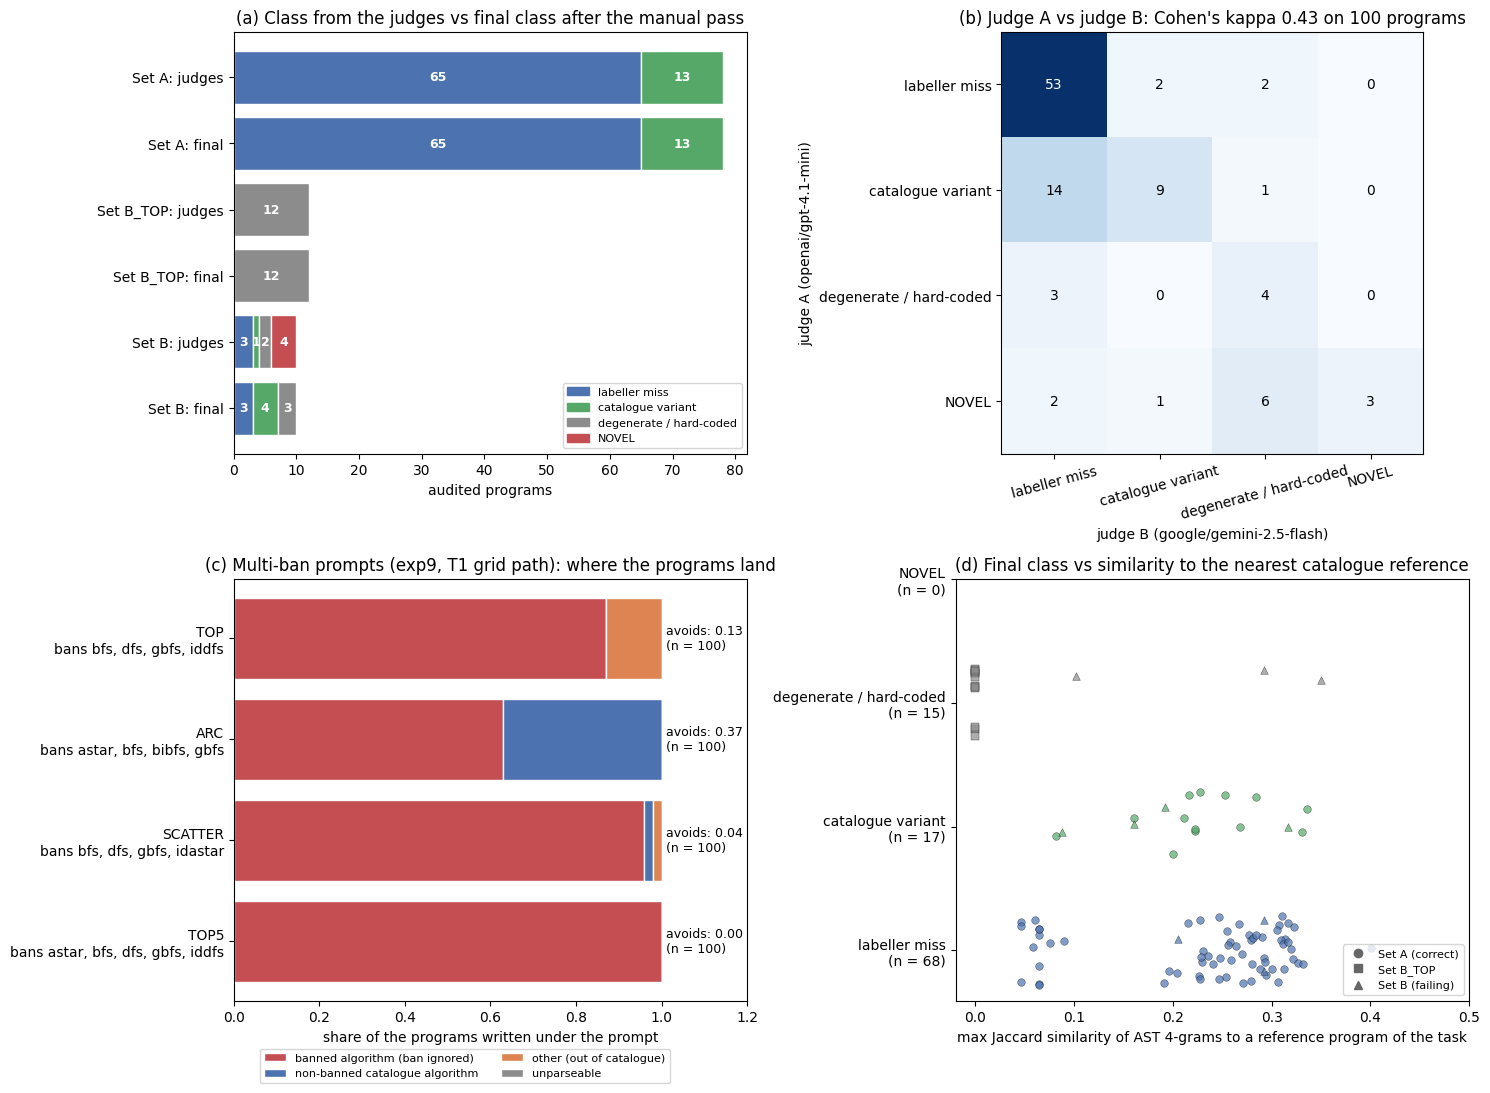

In [23]:
CLS = ["LABELLER_MISS", "CATALOGUE_VARIANT", "DEGENERATE_OR_HARDCODED", "NOVEL_ALGORITHM"]
SHORT = {"LABELLER_MISS": "labeller miss", "CATALOGUE_VARIANT": "catalogue variant",
         "DEGENERATE_OR_HARDCODED": "degenerate / hard-coded", "NOVEL_ALGORITHM": "NOVEL"}
COL = {"LABELLER_MISS": "#4C72B0", "CATALOGUE_VARIANT": "#55A868", "DEGENERATE_OR_HARDCODED": "#8C8C8C",
       "NOVEL_ALGORITHM": "#C44E52"}
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# (a) classes per set: the judges' call, then the final class after the manual pass
ax = axes[0, 0]
bars = [(f"Set {s}: {stage}", res[key][s]) for s in ("A", "B_TOP", "B")
        for stage, key in (("judges", "judge_only_class_counts"), ("final", "final_class_counts"))]
ys = np.arange(len(bars))[::-1]
for y, (_, d) in zip(ys, bars):
    left = 0
    for c in CLS:
        v = d.get(c, 0)
        if v:
            ax.barh(y, v, left=left, color=COL[c], edgecolor="white")
            ax.text(left + v / 2, y, str(v), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
            left += v
ax.set_yticks(ys, [b[0] for b in bars])
ax.set_xlabel("audited programs")
ax.set_title("(a) Class from the judges vs final class after the manual pass")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=COL[c]) for c in CLS], [SHORT[c] for c in CLS], loc="lower right",
          fontsize=8)

# (b) judge A vs judge B over every audited program
ax = axes[0, 1]
conf = res["confusion_A_rows_B_cols"]                      # {judge B class: {judge A class: n}}
M = np.array([[conf.get(b, {}).get(a, 0) for b in CLS] for a in CLS])
ax.imshow(M, cmap="Blues")
for i in range(len(CLS)):
    for j in range(len(CLS)):
        ax.text(j, i, M[i, j], ha="center", va="center", color="white" if M[i, j] > M.max() / 2 else "black")
ax.set_xticks(range(len(CLS)), [SHORT[c] for c in CLS], rotation=15)
ax.set_yticks(range(len(CLS)), [SHORT[c] for c in CLS])
ax.set_xlabel(f"judge B ({res['judges']['B']})")
ax.set_ylabel(f"judge A ({res['judges']['A']})")
ax.set_title(f"(b) Judge A vs judge B: Cohen's kappa {res['kappa_A_B']:.2f} on {M.sum()} programs")

# (c) exp9 multi-ban prompts: share of the 100 programs per landing type
ax = axes[1, 0]
parts = [("banned", "#C44E52", "banned algorithm (ban ignored)"), ("nonbanned_catalogue", "#4C72B0",
         "non-banned catalogue algorithm"), ("other", "#DD8452", "other (out of catalogue)"),
         ("unparseable", "#8C8C8C", "unparseable")]
names = [f"{a['condition'].split(':')[1]}\nbans {', '.join(a['banned_set'])}" for a in res["multiban_avoidance"]]
left = np.zeros(len(names))
for k, color, lab in parts:
    v = np.array([a[f"{k}_share"] for a in res["multiban_avoidance"]])
    ax.barh(names, v, left=left, color=color, label=lab, edgecolor="white")
    left += v
for i, a in enumerate(res["multiban_avoidance"]):
    ax.text(1.01, i, f"avoids: {a['avoidance_raw']:.2f}\n(n = {a['n']})", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1.2)
ax.set_xlabel("share of the programs written under the prompt")
ax.set_title("(c) Multi-ban prompts (exp9, T1 grid path): where the programs land")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.1), ncol=2, fontsize=8)

# (d) structural similarity of each audited program to the nearest catalogue reference program
ax = axes[1, 1]
jit = np.random.default_rng(0)
marks = {"A": ("o", "Set A (correct)"), "B_TOP": ("s", "Set B_TOP"), "B": ("^", "Set B (failing)")}
for i, c in enumerate(CLS):
    for s, (mk, _) in marks.items():
        v = [t["max_ast4_jaccard"] for t in res["table"] if t["final_class"] == c and t["set"] == s]
        if v:
            ax.scatter(v, i + jit.uniform(-0.28, 0.28, len(v)), marker=mk, color=COL[c], alpha=0.7, s=30,
                       edgecolor="black", linewidth=0.3)
ax.set_yticks(range(len(CLS)), [f"{SHORT[c]}\n(n = {sum(t['final_class'] == c for t in res['table'])})" for c in CLS])
ax.set_xlim(-0.02, max(0.5, max(t["max_ast4_jaccard"] for t in res["table"]) + 0.05))
ax.set_xlabel("max Jaccard similarity of AST 4-grams to a reference program of the task")
ax.set_title("(d) Final class vs similarity to the nearest catalogue reference")
ax.legend([plt.Line2D([], [], marker=mk, ls="", color="0.4") for mk, _ in marks.values()],
          [lab for _, lab in marks.values()], loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

## Summary

With all 100 demo programs, the artifact's own code reproduces the full run's novelty answer and checks it program by program.

* **Every program agrees with the full run.** All 100 programs and all 15 controls found their cached judge answers under the sha256 of the rebuilt prompt, so the demo reconstructs the full run's prompts byte for byte. For each program, the three judges' classes, the decision path, the final class and the AST similarity all equal the full run's (100/100).
* **No correct program is a new algorithm.** Set A, all 78 correct out-of-catalogue programs, is complete in the demo.
  * 65 of them are a catalogue algorithm the labeller missed, most often a unit-weight Dijkstra on the grid or a counting-sort selection on bench task T03.
  * The other 13 are named variants, such as SPFA without an in-queue flag, or Dijkstra and BFS hybrids.
  * Only one of the 78 drew a `NOVEL` call from any judge: gpt-4.1-mini, on that SPFA variant. Both other judges named the algorithm.
  * With 0 novel programs out of 78, the rule of three bounds the novel rate in this population at **3/78 = 0.038** (95%).
  * 62 of the 78 programs come from prompts that *forced* a particular algorithm ("write A\*", "write a unit-weight Dijkstra"), not from requests to be creative.
  * The four programs from conditions flagged as asking for something new all come from activation steering, and all four are known algorithms.
* **"Novel" is what the judges call broken code.**
  * The judges called 4 of the 10 failing Set B programs `NOVEL` (17 of 138 in the full run).
  * On reading, each is a degenerate program or a broken catalogue variant: a garbled path search, a recursive DFS wrapped in a heap, backtracking from the goal, a memoised DFS. Each override records its reason.
* **The judges are not reliable enough to use alone.**
  * Agreement between A and B is moderate: kappa 0.43 [0.28, 0.58] on these 100 programs, and 0.38 [0.31, 0.45] on all 228.
  * The positive controls fail the strict gate at 7/10, because IDDFS, Dial and bidirectional Dijkstra came back as "variants", even though both judges named the right algorithm in 10/10.
  * The negative controls pass 5/5, and the shuffled-names placebo scores 0/10, as it must.
* **Banning the most common algorithms does not push the model somewhere new.** The exp9 multi-ban prompts give:

| prompt | still use a banned algorithm | avoid the banned set | what the avoiders write |
|---|---|---|---|
| TOP | 87% | 13% | 12 degenerate failing programs and one unit-weight Dijkstra |
| ARC | 63% | 37% | all of them a non-banned catalogue algorithm |
| SCATTER | 96% | 4% | |
| TOP5 | 100% | 0% | |

**What the demo leaves out.**

* Its Set B holds 10 of the 138 programs, so its Set B counts, overall kappa and cache spend differ from the full run by construction.
* The other eight sections of `eval.py` need data the demo does not carry: likelihood scores, activation states, and all 31,269 records.
* To run the full evaluation, use `uv run eval.py` in the artifact folder. Its `reproducibility.md` lists the 11 dependency artifacts.